# 🎓 Projet Machine Learning — Adult Census Income Dataset

**Objectif métier** : Prédire si le revenu annuel d'une personne dépasse **50 000 $** à partir de données socio-démographiques issues du recensement américain de 1994.

**Pipeline complet :**
1. 📊 Compréhension Métier & Données (EDA)
2. 🧹 Data Cleaning (valeurs aberrantes, manquantes, redondantes)
3. 🔄 Data Transformation
4. 🎯 Feature Selection
5. 🛠️ Feature Engineering
6. 📉 ACP (Analyse en Composantes Principales)
7. 🤖 Entraînement & Évaluation des Modèles

## 📦 0. Installation des bibliothèques

In [1]:
# Installation si nécessaire
# !pip install pandas numpy matplotlib seaborn scikit-learn imbalanced-learn xgboost

import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, chi2, mutual_info_classif, RFE
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                              roc_auc_score, roc_curve, f1_score, precision_score, recall_score)
from scipy import stats

# Palette de couleurs
sns.set_style('whitegrid')
sns.set_palette('husl')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12

print('✅ Toutes les bibliothèques sont importées avec succès !')
print(f'Pandas: {pd.__version__} | NumPy: {np.__version__}')

✅ Toutes les bibliothèques sont importées avec succès !
Pandas: 2.2.3 | NumPy: 2.1.3


---
## 📊 PHASE 1 — Compréhension Métier & Exploration des Données (EDA)

### 1.1 Chargement des données

In [2]:
# Définition des colonnes (d'après adult.names)
COLUMNS = [
    'age', 'workclass', 'fnlwgt', 'education', 'education_num',
    'marital_status', 'occupation', 'relationship', 'race', 'sex',
    'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income'
]

# Chargement du fichier d'entraînement
df_train = pd.read_csv(
    'adult.data',
    names=COLUMNS,
    sep=',\s*',  # gestion des espaces après virgule
    engine='python',
    na_values='?'
)

# Chargement du fichier de test
df_test = pd.read_csv(
    'adult.test',
    names=COLUMNS,
    sep=',\s*',
    engine='python',
    na_values='?',
    skiprows=1  # la 1ère ligne du fichier test est un commentaire
)

# Nettoyage du point final dans income du fichier test
df_test['income'] = df_test['income'].str.rstrip('.')

# Fusion en un seul dataset pour le traitement global
df = pd.concat([df_train, df_test], ignore_index=True)

print(f'✅ Données chargées !')
print(f'   - Entraînement : {df_train.shape[0]:,} lignes × {df_train.shape[1]} colonnes')
print(f'   - Test         : {df_test.shape[0]:,} lignes × {df_test.shape[1]} colonnes')
print(f'   - Total        : {df.shape[0]:,} lignes × {df.shape[1]} colonnes')

✅ Données chargées !
   - Entraînement : 32,561 lignes × 15 colonnes
   - Test         : 16,281 lignes × 15 colonnes
   - Total        : 48,842 lignes × 15 colonnes


### 1.2 Description du dataset — Compréhension Métier

In [3]:
# Description des variables
description = {
    'Variable': COLUMNS,
    'Type': ['Continue', 'Catégorielle', 'Continue', 'Catégorielle', 'Continue',
             'Catégorielle', 'Catégorielle', 'Catégorielle', 'Catégorielle', 'Catégorielle',
             'Continue', 'Continue', 'Continue', 'Catégorielle', 'Cible'],
    'Description': [
        'Âge de la personne',
        'Secteur de travail (Public, Privé, Indépendant...)',
        'Poids final de recensement (pondération statistique)',
        'Niveau d\'éducation (libellé)',
        'Nombre d\'années d\'éducation',
        'Statut matrimonial',
        'Profession / Métier',
        'Relation familiale',
        'Origine ethnique',
        'Sexe',
        'Gains en capital (investissements)',
        'Pertes en capital',
        'Heures travaillées par semaine',
        'Pays d\'origine',
        'Revenu annuel : >50K ou <=50K'
    ]
}

desc_df = pd.DataFrame(description)
print('\n📋 Description des Variables Métier :')
print('='*80)
print(desc_df.to_string(index=False))


📋 Description des Variables Métier :
      Variable         Type                                          Description
           age     Continue                                   Âge de la personne
     workclass Catégorielle   Secteur de travail (Public, Privé, Indépendant...)
        fnlwgt     Continue Poids final de recensement (pondération statistique)
     education Catégorielle                         Niveau d'éducation (libellé)
 education_num     Continue                          Nombre d'années d'éducation
marital_status Catégorielle                                   Statut matrimonial
    occupation Catégorielle                                  Profession / Métier
  relationship Catégorielle                                   Relation familiale
          race Catégorielle                                     Origine ethnique
           sex Catégorielle                                                 Sexe
  capital_gain     Continue                   Gains en capital (investi

In [4]:
# Aperçu général
print('🔍 Aperçu des 5 premières lignes :')
df.head()

🔍 Aperçu des 5 premières lignes :


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [5]:
# Informations sur les types de données
print('📊 Informations sur le dataset :')
df.info()

📊 Informations sur le dataset :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48842 non-null  int64 
 1   workclass       46043 non-null  object
 2   fnlwgt          48842 non-null  int64 
 3   education       48842 non-null  object
 4   education_num   48842 non-null  int64 
 5   marital_status  48842 non-null  object
 6   occupation      46033 non-null  object
 7   relationship    48842 non-null  object
 8   race            48842 non-null  object
 9   sex             48842 non-null  object
 10  capital_gain    48842 non-null  int64 
 11  capital_loss    48842 non-null  int64 
 12  hours_per_week  48842 non-null  int64 
 13  native_country  47985 non-null  object
 14  income          48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB


In [6]:
# Statistiques descriptives des variables numériques
print('📈 Statistiques descriptives (variables numériques) :')
df.describe().T.style.background_gradient(cmap='Blues')

📈 Statistiques descriptives (variables numériques) :


,count,mean,std,min,25%,50%,75%,max
age,48842.000000,38.643585,13.710510,17.000000,28.000000,37.000000,48.000000,90.000000
fnlwgt,48842.000000,189664.134597,105604.025423,12285.000000,117550.500000,178144.500000,237642.000000,1490400.000000
education_num,48842.000000,10.078089,2.570973,1.000000,9.000000,10.000000,12.000000,16.000000
capital_gain,48842.000000,1079.067626,7452.019058,0.000000,0.000000,0.000000,0.000000,99999.000000
capital_loss,48842.000000,87.502314,403.004552,0.000000,0.000000,0.000000,0.000000,4356.000000
hours_per_week,48842.000000,40.422382,12.391444,1.000000,40.000000,40.000000,45.000000,99.000000


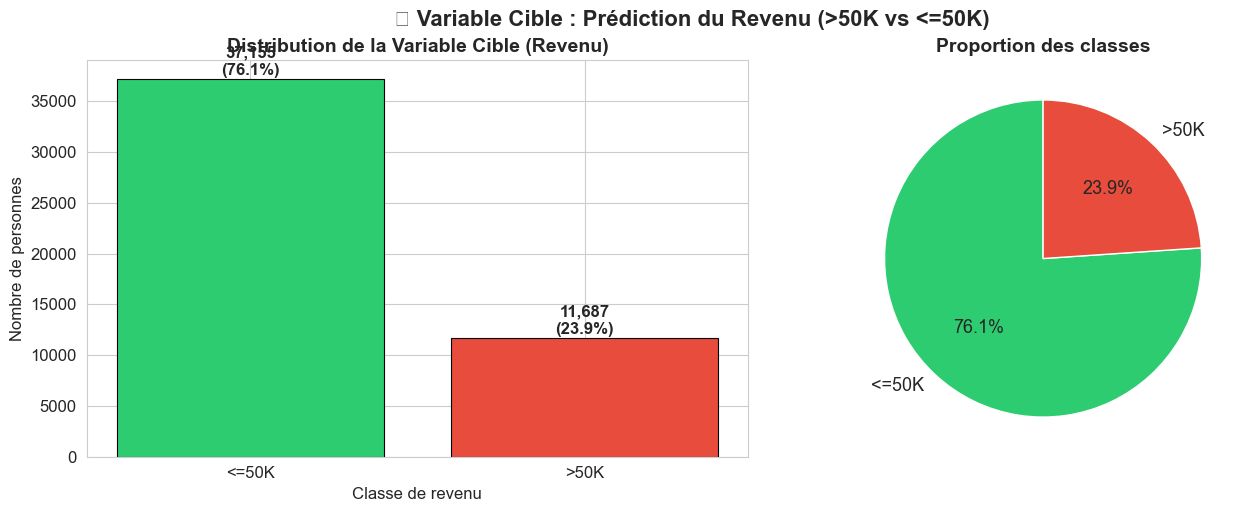


⚠️  Déséquilibre des classes : 76.1% vs 23.9%
    → Il faudra gérer ce déséquilibre lors de l'entraînement !


In [7]:
# Distribution de la variable cible
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

income_counts = df['income'].value_counts()
income_pct = df['income'].value_counts(normalize=True) * 100

# Graphique en barres
colors = ['#2ecc71', '#e74c3c']
bars = axes[0].bar(income_counts.index, income_counts.values, color=colors, edgecolor='black', linewidth=0.8)
axes[0].set_title('Distribution de la Variable Cible (Revenu)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Nombre de personnes')
axes[0].set_xlabel('Classe de revenu')
for bar, count, pct in zip(bars, income_counts.values, income_pct.values):
    axes[0].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 100,
                f'{count:,}\n({pct:.1f}%)', ha='center', va='bottom', fontweight='bold')

# Camembert
axes[1].pie(income_counts.values, labels=income_counts.index, colors=colors,
            autopct='%1.1f%%', startangle=90, textprops={'fontsize': 13})
axes[1].set_title('Proportion des classes', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.suptitle('🎯 Variable Cible : Prédiction du Revenu (>50K vs <=50K)', 
             fontsize=16, fontweight='bold', y=1.02)
plt.savefig('01_target_distribution.png', bbox_inches='tight', dpi=150)
plt.show()

print(f"\n⚠️  Déséquilibre des classes : {income_pct.iloc[0]:.1f}% vs {income_pct.iloc[1]:.1f}%")
print("    → Il faudra gérer ce déséquilibre lors de l'entraînement !")

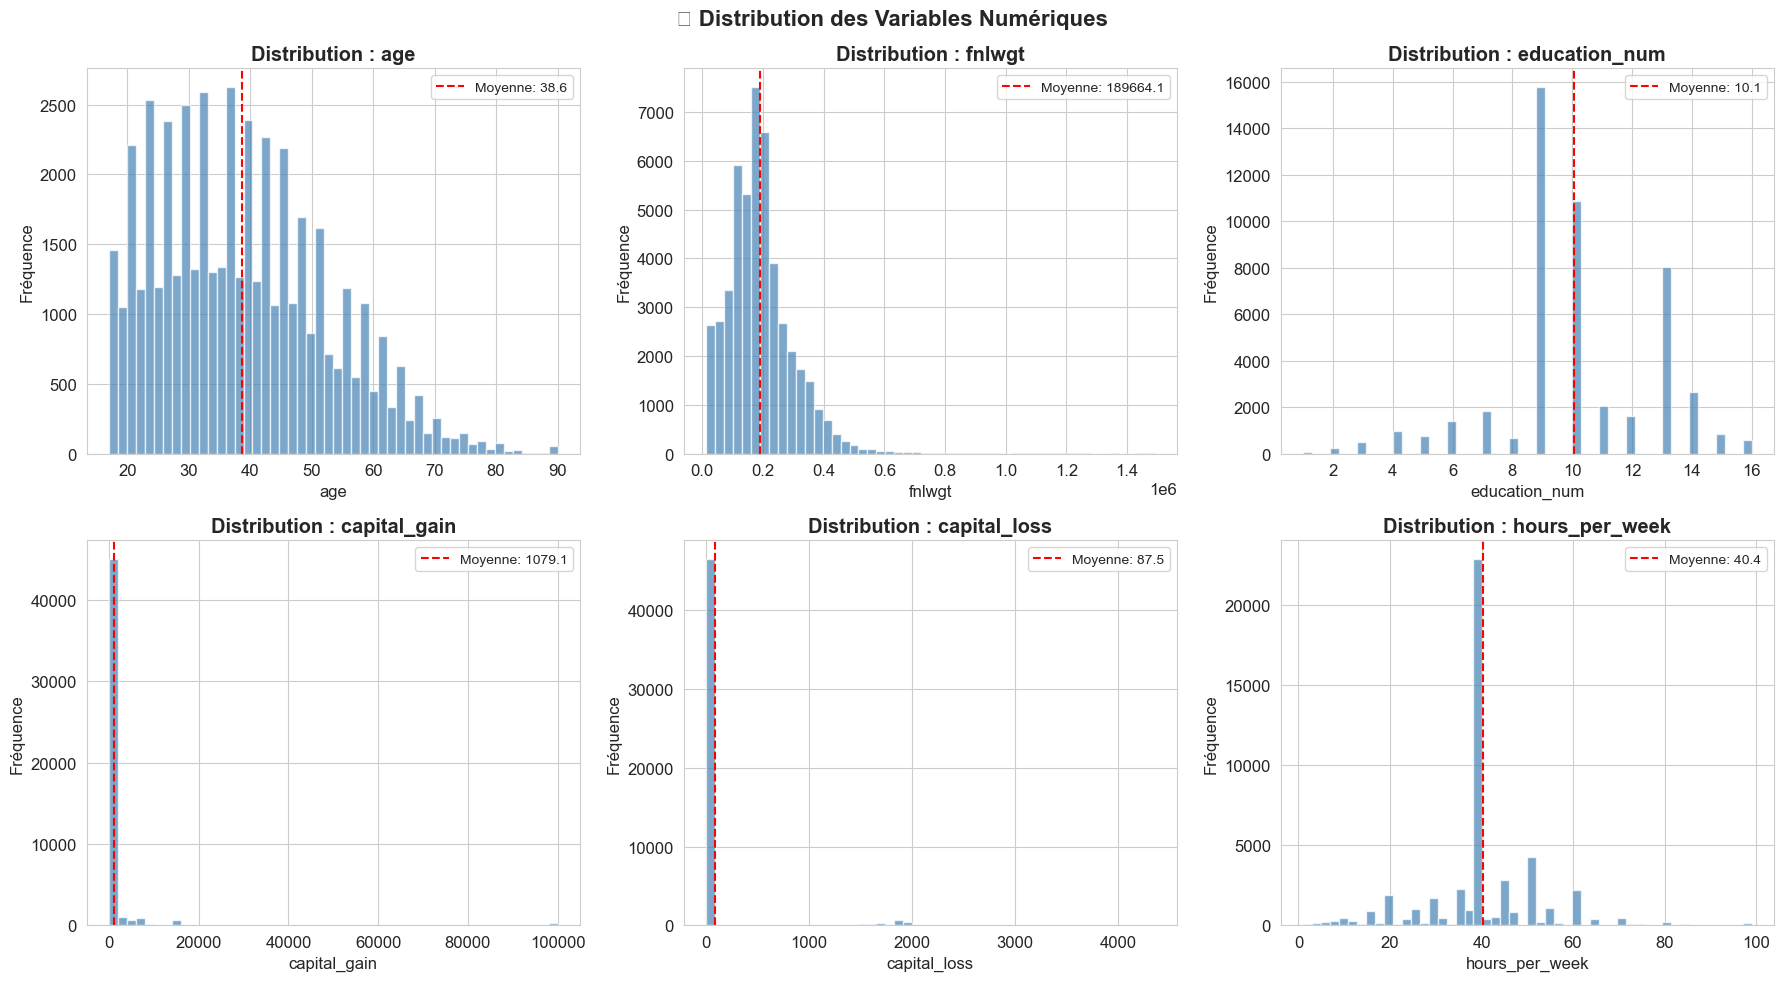

In [8]:
# Distribution des variables numériques
num_cols = ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    axes[i].hist(df[col], bins=50, color='steelblue', alpha=0.7, edgecolor='white')
    axes[i].set_title(f'Distribution : {col}', fontweight='bold')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Fréquence')
    # Ajout des statistiques
    mean_val = df[col].mean()
    axes[i].axvline(mean_val, color='red', linestyle='--', label=f'Moyenne: {mean_val:.1f}')
    axes[i].legend(fontsize=10)

plt.suptitle('📊 Distribution des Variables Numériques', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('02_numeric_distributions.png', bbox_inches='tight', dpi=150)
plt.show()

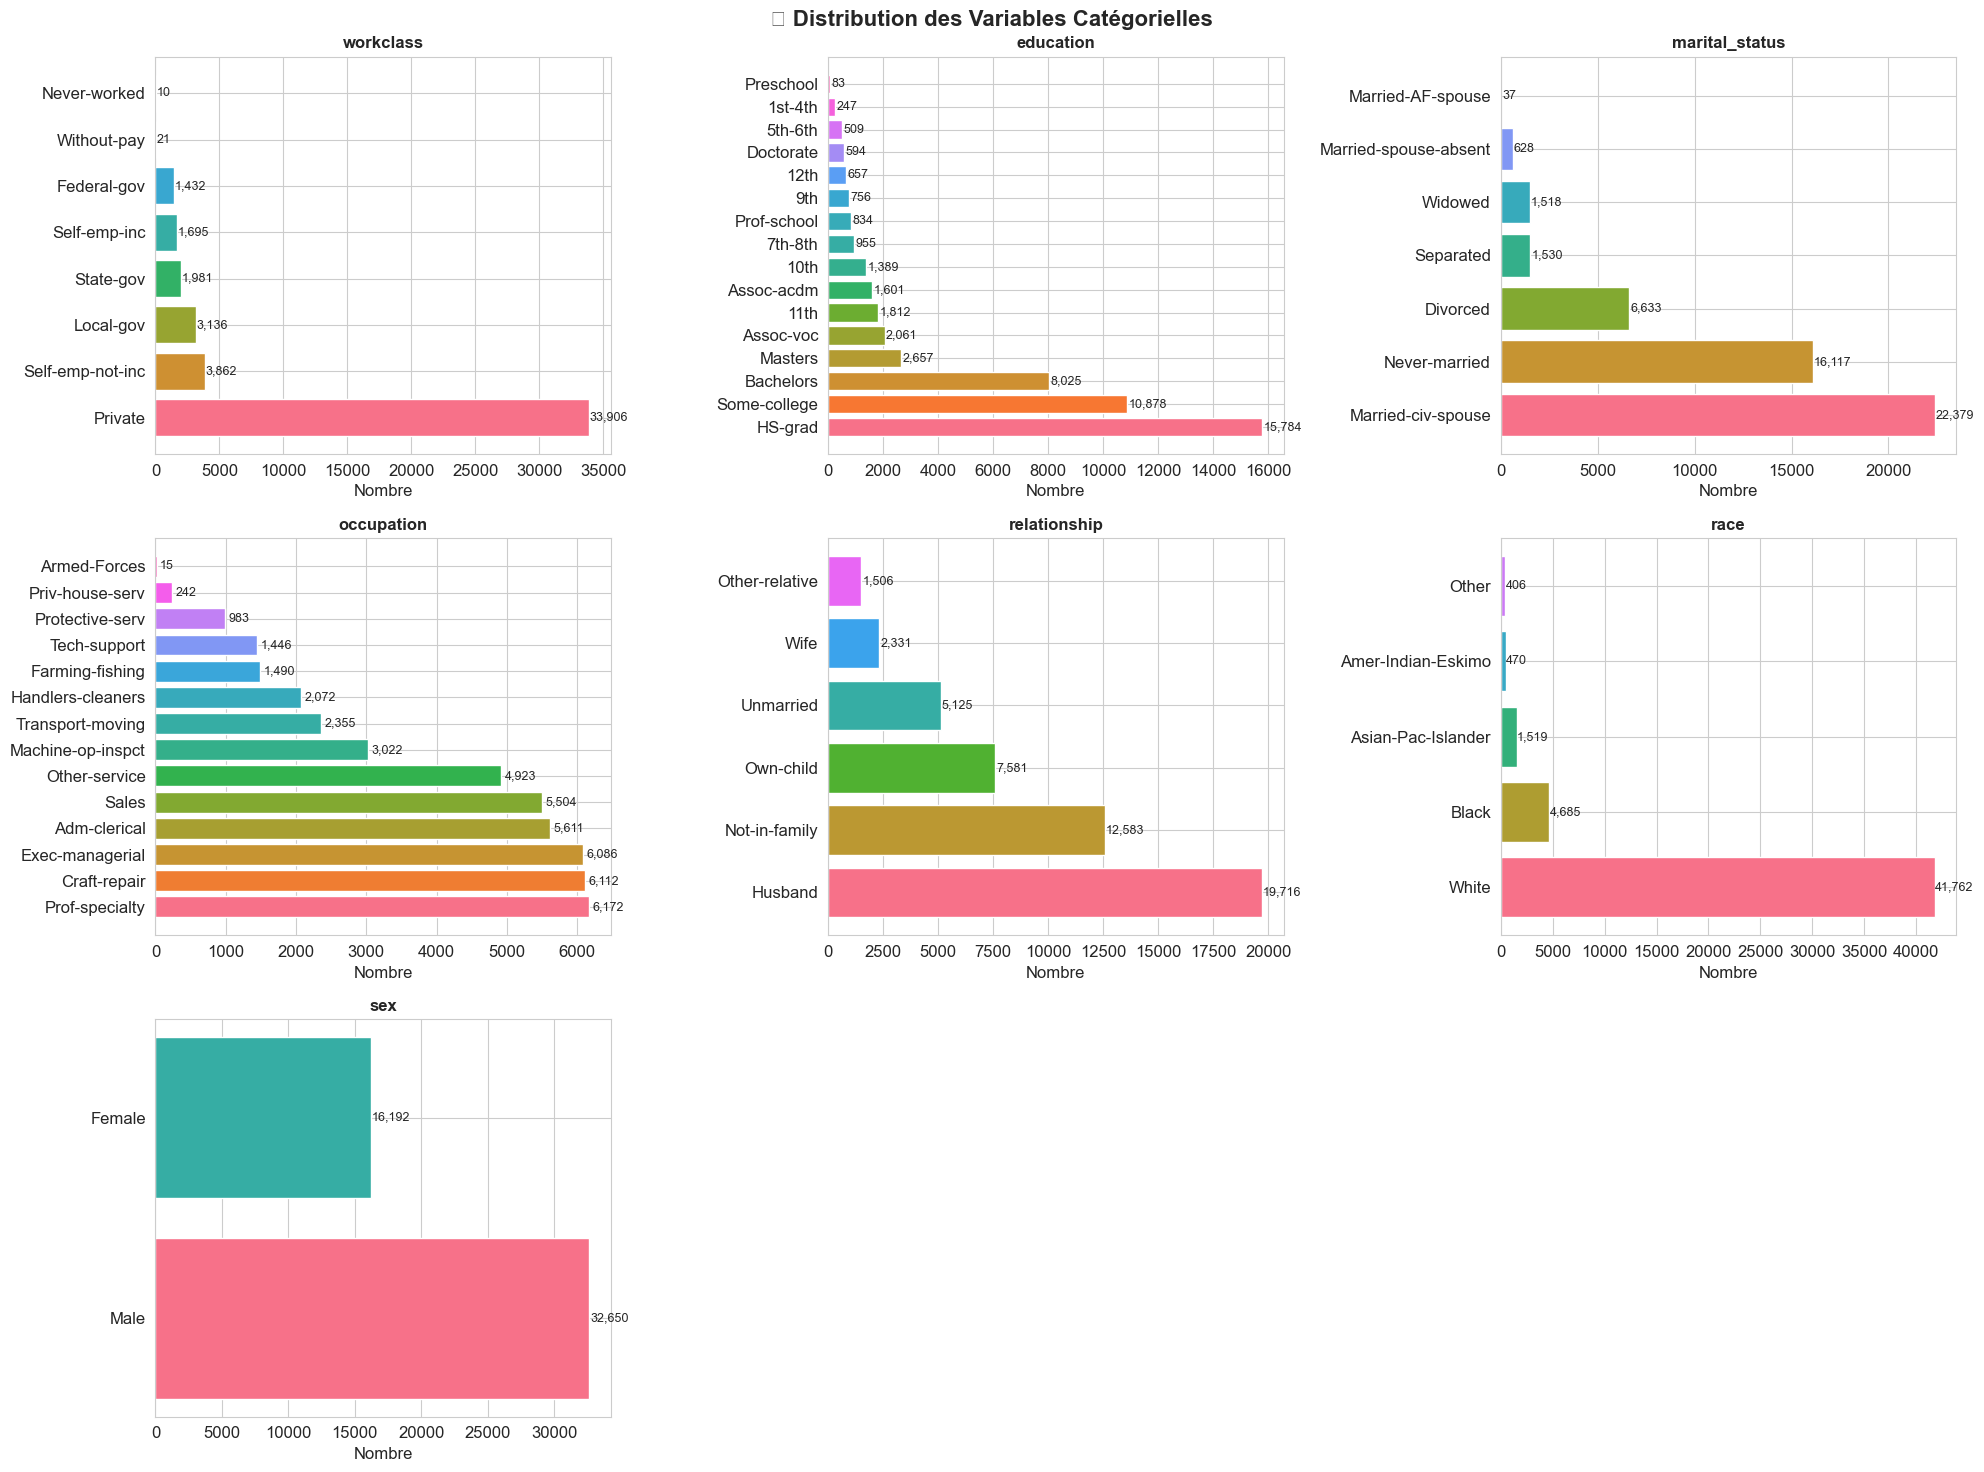

In [9]:
# Distribution des variables catégorielles
cat_cols = ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex']

fig, axes = plt.subplots(3, 3, figsize=(20, 15))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    value_counts = df[col].value_counts()
    axes[i].barh(value_counts.index, value_counts.values, color=sns.color_palette('husl', len(value_counts)))
    axes[i].set_title(f'{col}', fontweight='bold', fontsize=12)
    axes[i].set_xlabel('Nombre')
    for j, v in enumerate(value_counts.values):
        axes[i].text(v + 50, j, f'{v:,}', va='center', fontsize=9)

# Masquer les axes inutilisés
for i in range(len(cat_cols), len(axes)):
    axes[i].set_visible(False)

plt.suptitle('📊 Distribution des Variables Catégorielles', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('03_categorical_distributions.png', bbox_inches='tight', dpi=150)
plt.show()

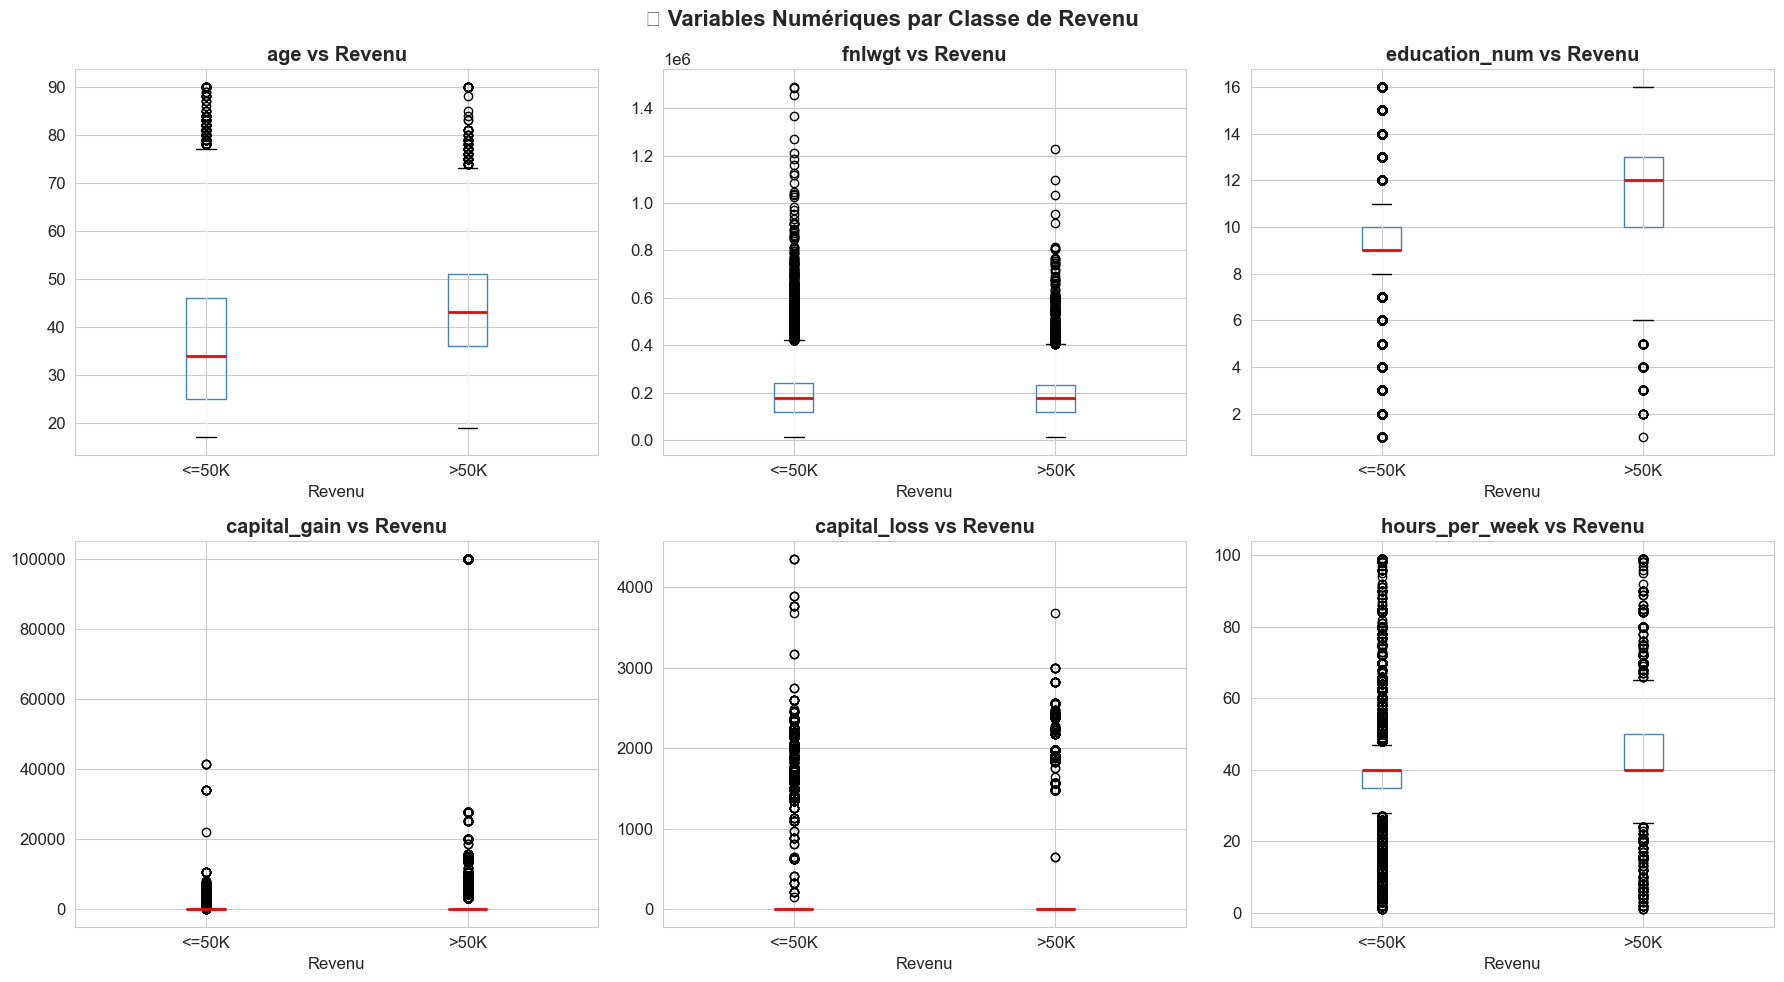

In [10]:
# Analyse bivariée : revenu vs variables numériques
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    df.boxplot(column=col, by='income', ax=axes[i], 
               boxprops=dict(color='steelblue'),
               medianprops=dict(color='red', linewidth=2))
    axes[i].set_title(f'{col} vs Revenu', fontweight='bold')
    axes[i].set_xlabel('Revenu')

plt.suptitle('📈 Variables Numériques par Classe de Revenu', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('04_bivariate_analysis.png', bbox_inches='tight', dpi=150)
plt.show()

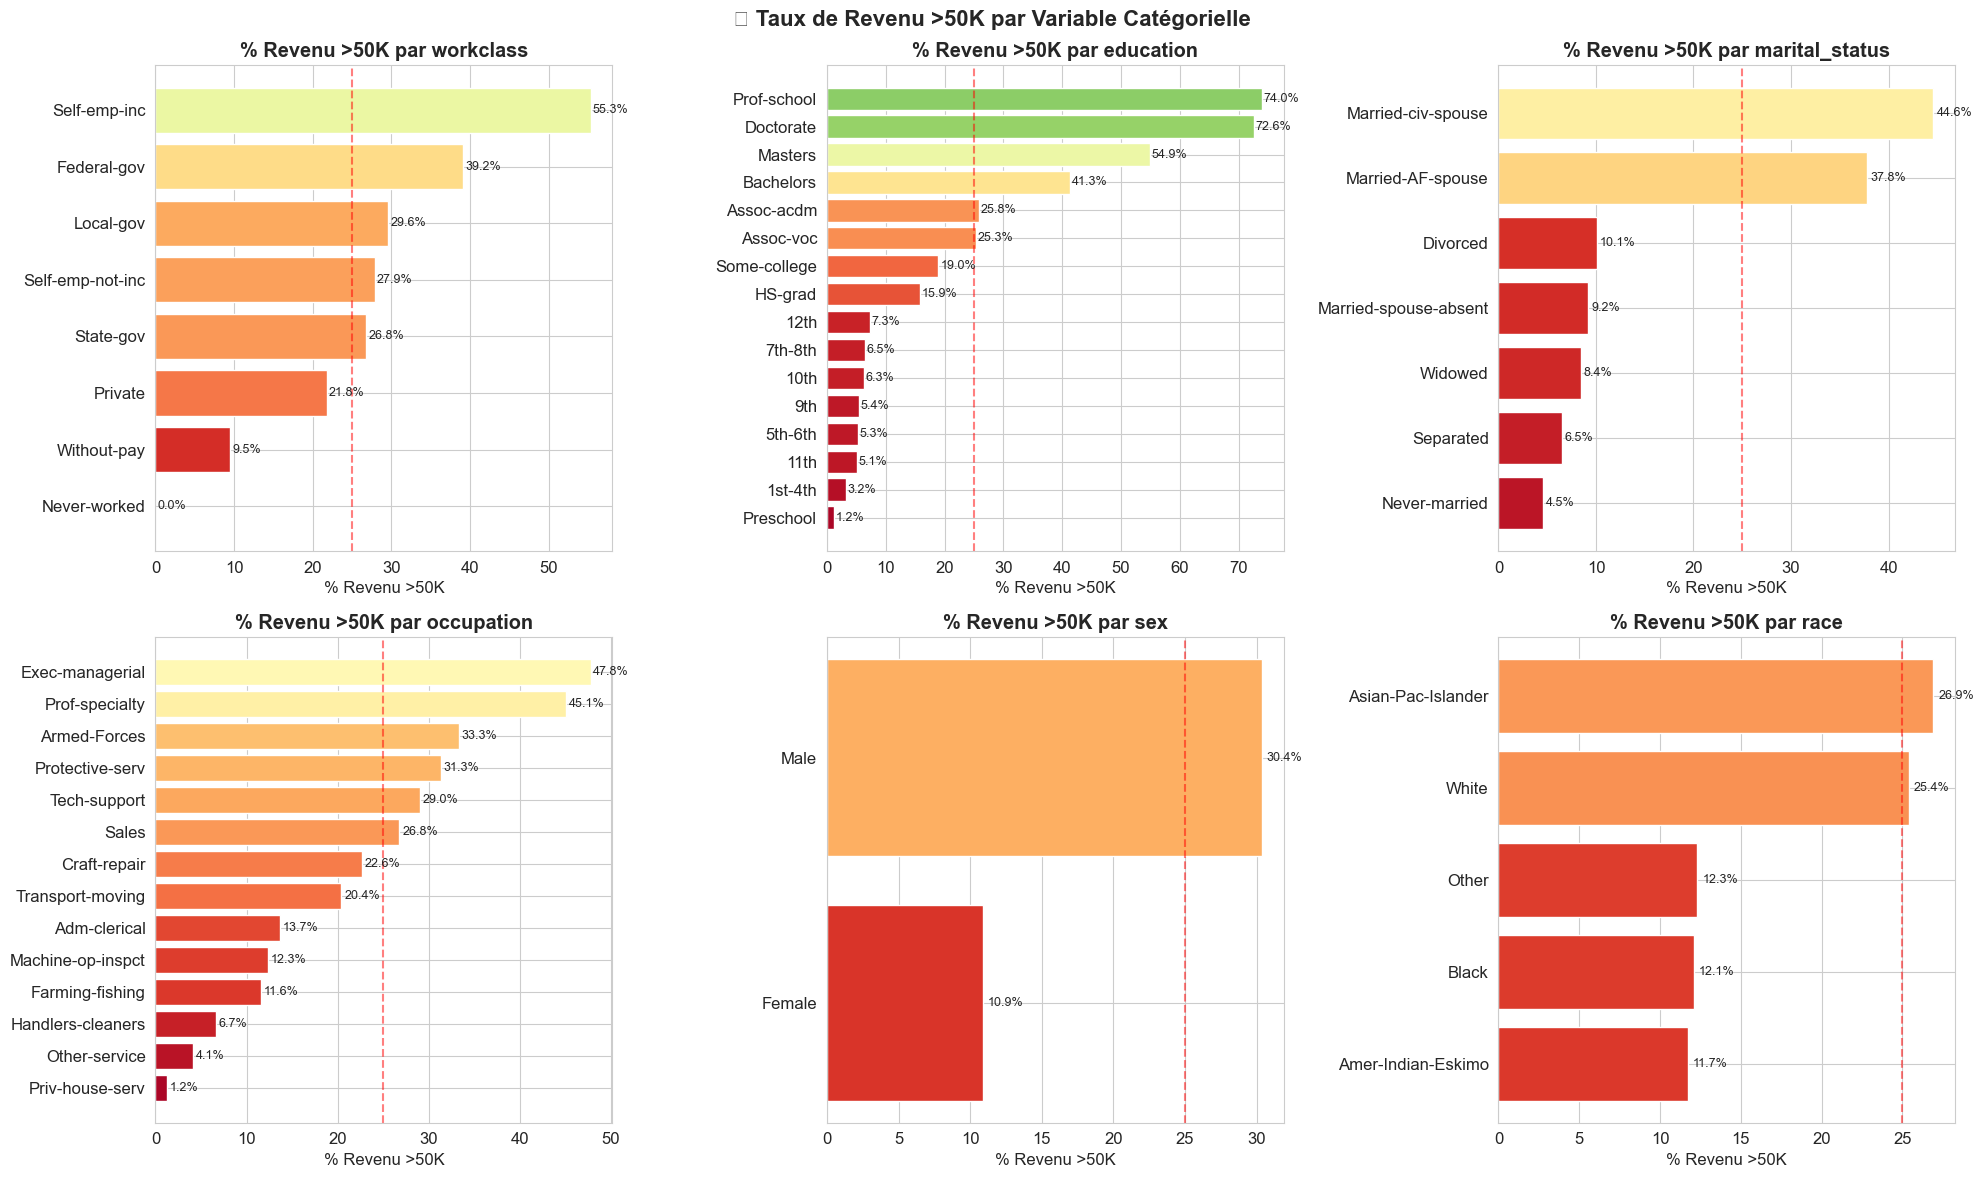

In [11]:
# Analyse bivariée : revenu vs variables catégorielles
cat_bivariate = ['workclass', 'education', 'marital_status', 'occupation', 'sex', 'race']

fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.flatten()

for i, col in enumerate(cat_bivariate):
    income_rate = df.groupby(col)['income'].apply(lambda x: (x == '>50K').sum() / len(x) * 100)
    income_rate = income_rate.sort_values(ascending=True)
    bars = axes[i].barh(income_rate.index, income_rate.values, 
                        color=plt.cm.RdYlGn(income_rate.values / 100))
    axes[i].set_title(f'% Revenu >50K par {col}', fontweight='bold')
    axes[i].set_xlabel('% Revenu >50K')
    axes[i].axvline(x=25, color='red', linestyle='--', alpha=0.5, label='Moyenne globale')
    for bar, val in zip(bars, income_rate.values):
        axes[i].text(val + 0.3, bar.get_y() + bar.get_height()/2., 
                    f'{val:.1f}%', va='center', fontsize=9)

plt.suptitle('📊 Taux de Revenu >50K par Variable Catégorielle', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('05_categorical_bivariate.png', bbox_inches='tight', dpi=150)
plt.show()

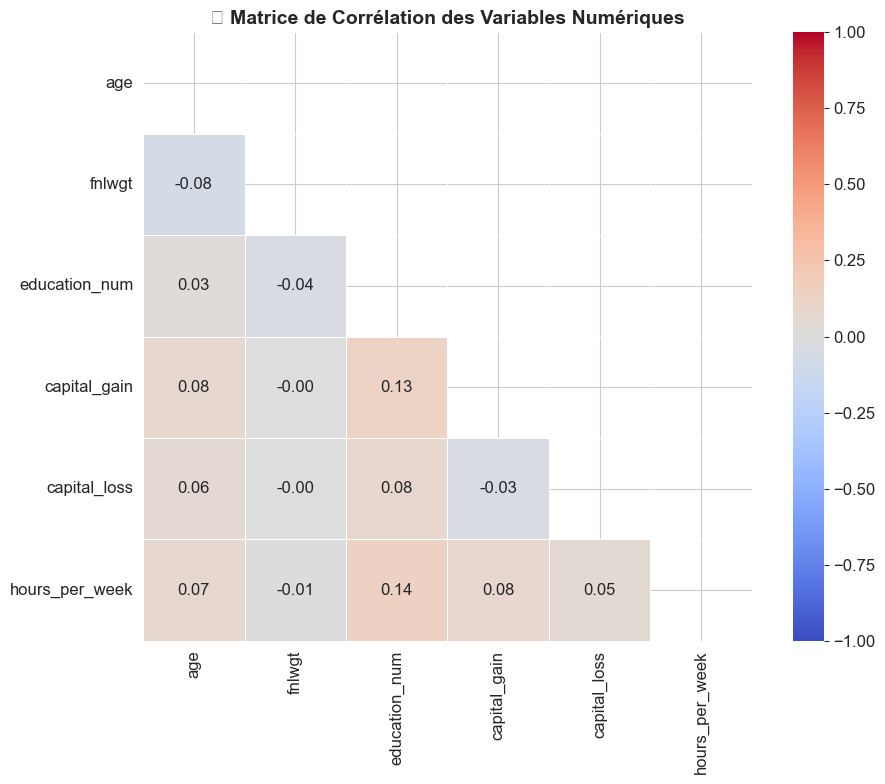


💡 Observations clés :
   - education vs education_num : corrélation = -0.039
   - education et education_num sont REDONDANTES (même info, formes différentes)


In [12]:
# Matrice de corrélation des variables numériques
corr_matrix = df[num_cols].corr()

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', 
            cmap='coolwarm', center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5)
plt.title('🔗 Matrice de Corrélation des Variables Numériques', 
          fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('06_correlation_matrix.png', bbox_inches='tight', dpi=150)
plt.show()

print("\n💡 Observations clés :")
print(f"   - education vs education_num : corrélation = {corr_matrix.loc['education_num', 'fnlwgt']:.3f}")
print("   - education et education_num sont REDONDANTES (même info, formes différentes)")

---
## 🧹 PHASE 2 — Data Cleaning

### 2.1 Analyse des valeurs manquantes

🔍 Analyse des Valeurs Manquantes :
       Colonne  Valeurs Manquantes  Pourcentage (%)
    occupation                2809         5.751198
     workclass                2799         5.730724
native_country                 857         1.754637


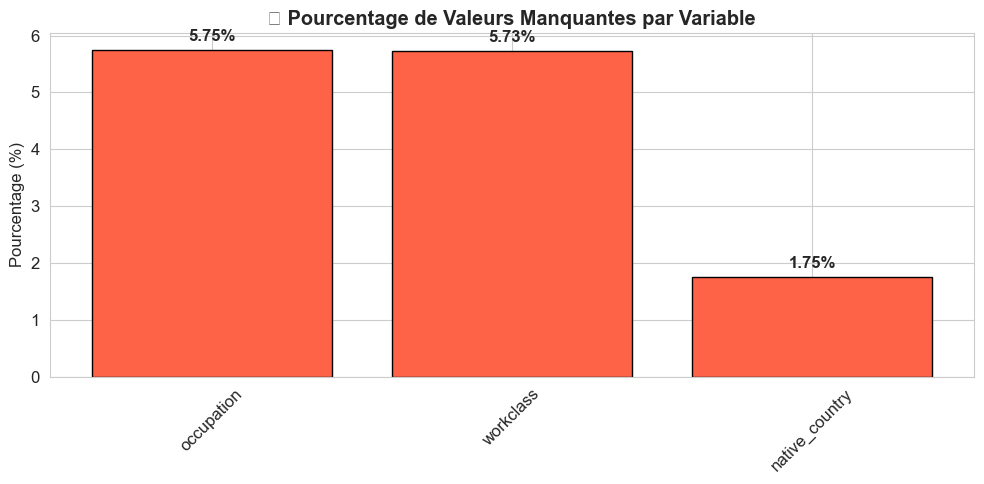

In [13]:
# Analyse complète des valeurs manquantes
missing_df = pd.DataFrame({
    'Colonne': df.columns,
    'Valeurs Manquantes': df.isnull().sum().values,
    'Pourcentage (%)': (df.isnull().sum() / len(df) * 100).values
})
missing_df = missing_df[missing_df['Valeurs Manquantes'] > 0].sort_values('Valeurs Manquantes', ascending=False)

print('🔍 Analyse des Valeurs Manquantes :')
print('='*50)
print(missing_df.to_string(index=False))

# Visualisation
if not missing_df.empty:
    plt.figure(figsize=(10, 5))
    bars = plt.bar(missing_df['Colonne'], missing_df['Pourcentage (%)'], 
                   color='tomato', edgecolor='black')
    plt.title('📊 Pourcentage de Valeurs Manquantes par Variable', fontweight='bold')
    plt.ylabel('Pourcentage (%)')
    plt.xticks(rotation=45)
    for bar, pct in zip(bars, missing_df['Pourcentage (%)']):
        plt.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.1,
                f'{pct:.2f}%', ha='center', va='bottom', fontweight='bold')
    plt.tight_layout()
    plt.savefig('07_missing_values.png', bbox_inches='tight', dpi=150)
    plt.show()
else:
    print("✅ Aucune valeur manquante détectée (les '?' ont été convertis en NaN)")

In [14]:
# Stratégie de traitement des valeurs manquantes
print('📋 Stratégie de traitement :')
print('   - workclass  : Mode (valeur la plus fréquente = "Private")')
print('   - occupation : Mode (valeur la plus fréquente)')
print('   - native_country : Mode ("United-States" majoritaire à >90%)')
print()

# Copie de travail
df_clean = df.copy()

# Imputation par le mode pour les catégorielles
for col in ['workclass', 'occupation', 'native_country']:
    mode_val = df_clean[col].mode()[0]
    missing_count = df_clean[col].isnull().sum()
    df_clean[col].fillna(mode_val, inplace=True)
    print(f'   ✅ {col}: {missing_count} valeurs manquantes → remplacées par "{mode_val}"')

print(f'\n✅ Valeurs manquantes restantes : {df_clean.isnull().sum().sum()}')

📋 Stratégie de traitement :
   - workclass  : Mode (valeur la plus fréquente = "Private")
   - occupation : Mode (valeur la plus fréquente)
   - native_country : Mode ("United-States" majoritaire à >90%)

   ✅ workclass: 2799 valeurs manquantes → remplacées par "Private"
   ✅ occupation: 2809 valeurs manquantes → remplacées par "Prof-specialty"
   ✅ native_country: 857 valeurs manquantes → remplacées par "United-States"

✅ Valeurs manquantes restantes : 0


### 2.2 Détection et traitement des valeurs aberrantes (Outliers)

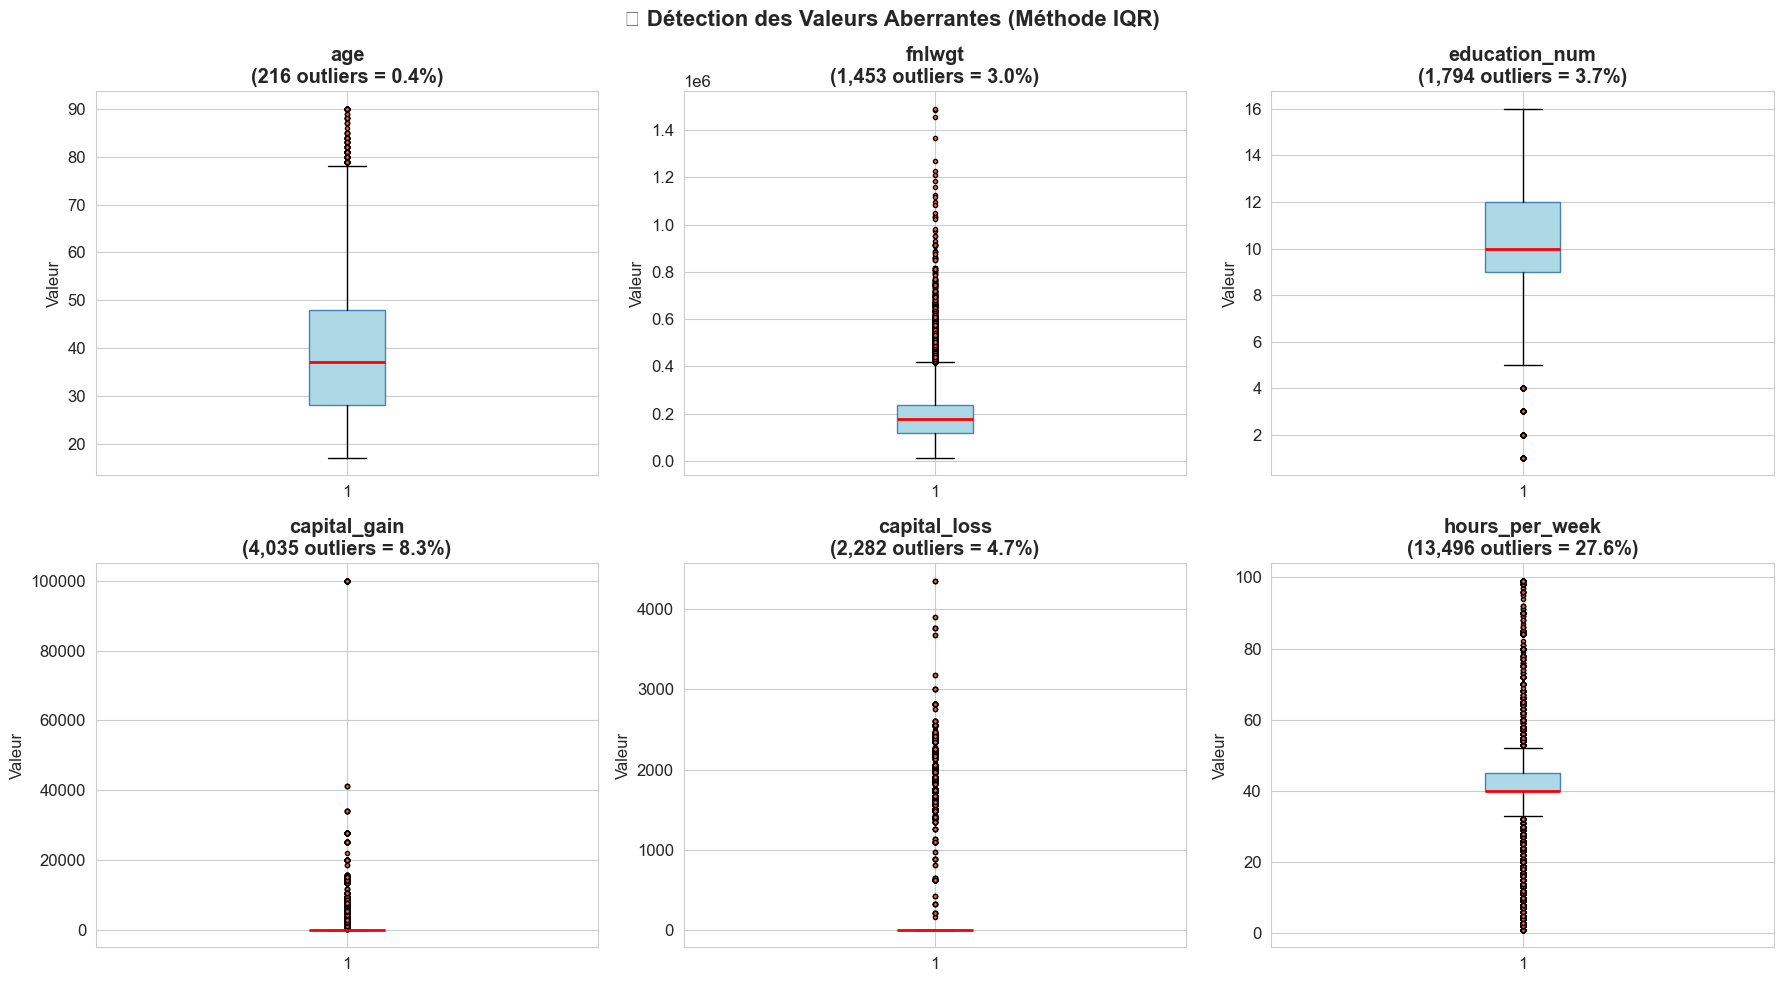


📋 Résumé des Outliers :
      Variable  Borne Inf.  Borne Sup.  N Outliers  % Outliers
           age       -2.00       78.00         216        0.44
        fnlwgt   -62586.75   417779.25        1453        2.97
 education_num        4.50       16.50        1794        3.67
  capital_gain        0.00        0.00        4035        8.26
  capital_loss        0.00        0.00        2282        4.67
hours_per_week       32.50       52.50       13496       27.63


In [15]:
# Visualisation des boîtes à moustaches AVANT traitement
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

outlier_summary = []

for i, col in enumerate(num_cols):
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    n_outliers = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()
    pct_outliers = n_outliers / len(df_clean) * 100
    
    outlier_summary.append({
        'Variable': col, 'Q1': Q1, 'Q3': Q3, 'IQR': IQR,
        'Borne Inf.': lower, 'Borne Sup.': upper,
        'N Outliers': n_outliers, '% Outliers': round(pct_outliers, 2)
    })
    
    axes[i].boxplot(df_clean[col].dropna(), vert=True, patch_artist=True,
                   boxprops=dict(facecolor='lightblue', color='steelblue'),
                   medianprops=dict(color='red', linewidth=2),
                   flierprops=dict(marker='o', markerfacecolor='tomato', markersize=3))
    axes[i].set_title(f'{col}\n({n_outliers:,} outliers = {pct_outliers:.1f}%)', fontweight='bold')
    axes[i].set_ylabel('Valeur')

plt.suptitle('🔍 Détection des Valeurs Aberrantes (Méthode IQR)', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('08_outliers_detection.png', bbox_inches='tight', dpi=150)
plt.show()

outlier_df = pd.DataFrame(outlier_summary)
print('\n📋 Résumé des Outliers :')
print(outlier_df[['Variable', 'Borne Inf.', 'Borne Sup.', 'N Outliers', '% Outliers']].to_string(index=False))

In [16]:
# Analyse spécifique : capital_gain et capital_loss
print('💡 Analyse métier des outliers :')
print()
print('📌 capital_gain & capital_loss :')
print(f'   - 91.7% des personnes ont capital_gain = 0 et capital_loss = 0')
print(f'   - Les valeurs élevées sont légitimes (investissements réels)')
print(f'   - Stratégie : GARDER mais créer des features binaires')
print()
print('📌 age :')
print(f'   - age max = {df_clean["age"].max()}, plausible pour un recensement')
print(f'   - Valeurs extrêmes légitimes, pas d\'aberration réelle')
print()
print('📌 hours_per_week :')
print(f'   - max = {df_clean["hours_per_week"].max()} heures/semaine → aberrant !')
print(f'   - 1-168h plausible, mais >99h très suspect')
print(f'   - Stratégie : Capping (winsorizing) à 99h max')
print()
print('📌 fnlwgt :')
print(f'   - Poids statistique du recensement, pas une variable prédictive réelle')
print(f'   - Sera supprimé en Phase 4 (Feature Selection)')

💡 Analyse métier des outliers :

📌 capital_gain & capital_loss :
   - 91.7% des personnes ont capital_gain = 0 et capital_loss = 0
   - Les valeurs élevées sont légitimes (investissements réels)
   - Stratégie : GARDER mais créer des features binaires

📌 age :
   - age max = 90, plausible pour un recensement
   - Valeurs extrêmes légitimes, pas d'aberration réelle

📌 hours_per_week :
   - max = 99 heures/semaine → aberrant !
   - 1-168h plausible, mais >99h très suspect
   - Stratégie : Capping (winsorizing) à 99h max

📌 fnlwgt :
   - Poids statistique du recensement, pas une variable prédictive réelle
   - Sera supprimé en Phase 4 (Feature Selection)


In [17]:
# Traitement des outliers
df_clean_2 = df_clean.copy()

# 1. Capping de hours_per_week à 99h
n_capped = (df_clean_2['hours_per_week'] > 99).sum()
df_clean_2['hours_per_week'] = df_clean_2['hours_per_week'].clip(upper=99)
print(f'✅ hours_per_week : {n_capped} valeurs > 99h → cappées à 99h')

# 2. Vérification de l'âge
age_outliers = df_clean_2[(df_clean_2['age'] < 15) | (df_clean_2['age'] > 95)]
print(f'   age : {len(age_outliers)} lignes avec âge <15 ou >95 (conservées, plausibles)')

# 3. capital_gain et capital_loss : garder tels quels (seront engineered)
print(f'   capital_gain & capital_loss : conservés (feature engineering à venir)')

print(f'\n✅ Traitement des outliers terminé. Shape : {df_clean_2.shape}')

✅ hours_per_week : 0 valeurs > 99h → cappées à 99h
   age : 0 lignes avec âge <15 ou >95 (conservées, plausibles)
   capital_gain & capital_loss : conservés (feature engineering à venir)

✅ Traitement des outliers terminé. Shape : (48842, 15)


### 2.3 Détection et suppression des doublons

In [18]:
# Recherche des doublons
n_duplicates = df_clean_2.duplicated().sum()
print(f'🔍 Nombre de lignes dupliquées : {n_duplicates}')
print(f'   (Rappel : le fichier adult.names mentionne 6 instances conflictuelles)')

if n_duplicates > 0:
    print(f'\n📋 Exemples de doublons :')
    print(df_clean_2[df_clean_2.duplicated(keep=False)].head(10))
    df_clean_2 = df_clean_2.drop_duplicates()
    print(f'\n✅ {n_duplicates} doublons supprimés. Nouveau shape : {df_clean_2.shape}')
else:
    print('✅ Aucun doublon exact détecté.')

🔍 Nombre de lignes dupliquées : 53
   (Rappel : le fichier adult.names mentionne 6 instances conflictuelles)

📋 Exemples de doublons :


      age workclass  fnlwgt     education  education_num      marital_status  \
2195   39   Private  184659       HS-grad              9  Married-civ-spouse   
2303   90   Private   52386  Some-college             10       Never-married   
3118   19   Private  130431       5th-6th              3       Never-married   
3445   41   Private  116391     Bachelors             13  Married-civ-spouse   
3917   19   Private  251579  Some-college             10       Never-married   
4325   25   Private  308144     Bachelors             13       Never-married   
4767   21   Private  250051  Some-college             10       Never-married   
4881   25   Private  308144     Bachelors             13       Never-married   
4940   38   Private  207202       HS-grad              9  Married-civ-spouse   
5104   90   Private   52386  Some-college             10       Never-married   

             occupation   relationship                race     sex  \
2195  Machine-op-inspct        Husband           


✅ 53 doublons supprimés. Nouveau shape : (48789, 15)


### 2.4 Gestion des données redondantes

In [19]:
# Analyse de la redondance entre 'education' et 'education_num'
edu_mapping = df_clean_2.groupby('education')['education_num'].unique()
print('📊 Correspondance Education ↔ Education_num :')
print(edu_mapping.to_string())
print()

# Vérification : chaque éducation correspond à UN SEUL numéro
is_bijection = all(len(v) == 1 for v in edu_mapping.values)
print(f'✅ Bijection parfaite (1 texte = 1 numéro) : {is_bijection}')
print('   → La variable "education" est REDONDANTE avec "education_num"')
print('   → On supprimera "education" (garde le numérique plus informatif pour ML)')

📊 Correspondance Education ↔ Education_num :
education
10th             [6]
11th             [7]
12th             [8]
1st-4th          [2]
5th-6th          [3]
7th-8th          [4]
9th              [5]
Assoc-acdm      [12]
Assoc-voc       [11]
Bachelors       [13]
Doctorate       [16]
HS-grad          [9]
Masters         [14]
Preschool        [1]
Prof-school     [15]
Some-college    [10]

✅ Bijection parfaite (1 texte = 1 numéro) : True
   → La variable "education" est REDONDANTE avec "education_num"
   → On supprimera "education" (garde le numérique plus informatif pour ML)


In [20]:
# Résumé du Data Cleaning
print('='*60)
print('📋 RÉSUMÉ — DATA CLEANING COMPLET')
print('='*60)
print(f'  Taille initiale  : {df.shape}')
print(f'  Taille finale    : {df_clean_2.shape}')
print(f'  Valeurs manquantes traitées : ✅')
print(f'  Outliers traités (capping) : ✅')
print(f'  Doublons supprimés : {n_duplicates}')
print(f'  Redondances identifiées : education ↔ education_num')
print('='*60)

📋 RÉSUMÉ — DATA CLEANING COMPLET
  Taille initiale  : (48842, 15)
  Taille finale    : (48789, 15)
  Valeurs manquantes traitées : ✅
  Outliers traités (capping) : ✅
  Doublons supprimés : 53
  Redondances identifiées : education ↔ education_num


---
## 🔄 PHASE 3 — Data Transformation

In [21]:
df_transformed = df_clean_2.copy()

# ── 3.1 Encodage de la variable cible ──────────────────────────────────────
df_transformed['income_binary'] = (df_transformed['income'] == '>50K').astype(int)
print('✅ Variable cible encodée :')
print('   >50K  → 1')
print('   <=50K → 0')
print(df_transformed['income_binary'].value_counts())
print()

✅ Variable cible encodée :
   >50K  → 1
   <=50K → 0
income_binary
0    37108
1    11681
Name: count, dtype: int64



In [22]:
# ── 3.2 Suppression des colonnes redondantes ────────────────────────────────
df_transformed = df_transformed.drop(columns=['income', 'education'])
print('✅ Colonnes supprimées :')
print('   - income    (remplacée par income_binary)')
print('   - education (redondante avec education_num)')
print(f'   Shape actuelle : {df_transformed.shape}')

✅ Colonnes supprimées :
   - income    (remplacée par income_binary)
   - education (redondante avec education_num)
   Shape actuelle : (48789, 14)


In [23]:
# ── 3.3 Encodage des variables catégorielles ────────────────────────────────
# Stratégie :
#   - Variables binaires (sex, income) : Label Encoding
#   - Variables nominales (workclass, occupation, etc.) : One-Hot Encoding

# Variables pour OHE (faible cardinalité)
cat_ohe = ['workclass', 'marital_status', 'occupation', 'relationship', 'race', 'sex']

# native_country : trop de modalités → regroupement + OHE
# On garde les 5 pays les plus fréquents et regroupe le reste en "Other"
top_countries = df_transformed['native_country'].value_counts().nlargest(5).index
df_transformed['native_country_grouped'] = df_transformed['native_country'].apply(
    lambda x: x if x in top_countries else 'Other'
)
df_transformed = df_transformed.drop(columns=['native_country'])

cat_ohe_extended = cat_ohe + ['native_country_grouped']

print('📊 Cardinalité avant encodage :')
for col in cat_ohe_extended:
    print(f'   {col}: {df_transformed[col].nunique()} modalités')

# One-Hot Encoding
df_transformed = pd.get_dummies(df_transformed, columns=cat_ohe_extended, drop_first=True)
print(f'\n✅ OHE appliqué. Shape après encodage : {df_transformed.shape}')

📊 Cardinalité avant encodage :
   workclass: 8 modalités
   marital_status: 7 modalités
   occupation: 14 modalités


   relationship: 6 modalités
   race: 5 modalités
   sex: 2 modalités


   native_country_grouped: 6 modalités



✅ OHE appliqué. Shape après encodage : (48789, 48)


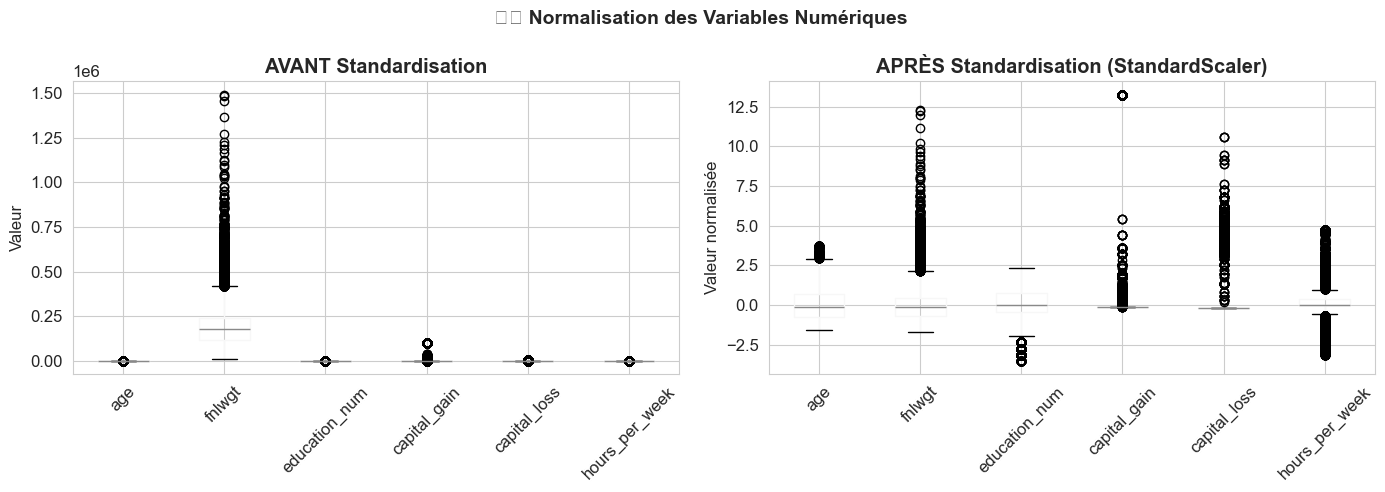

✅ StandardScaler appliqué sur les variables numériques
   Moyenne ≈ 0, Écart-type ≈ 1 pour chaque feature


In [24]:
# ── 3.4 Normalisation / Standardisation des variables numériques ─────────────
num_features = ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']

# Visualisation AVANT standardisation
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
df_transformed[num_features].boxplot(ax=axes[0], rot=45)
axes[0].set_title('AVANT Standardisation', fontweight='bold')
axes[0].set_ylabel('Valeur')

# Application du StandardScaler
scaler = StandardScaler()
df_transformed_scaled = df_transformed.copy()
df_transformed_scaled[num_features] = scaler.fit_transform(df_transformed[num_features])

df_transformed_scaled[num_features].boxplot(ax=axes[1], rot=45)
axes[1].set_title('APRÈS Standardisation (StandardScaler)', fontweight='bold')
axes[1].set_ylabel('Valeur normalisée')

plt.suptitle('⚖️ Normalisation des Variables Numériques', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('09_scaling.png', bbox_inches='tight', dpi=150)
plt.show()

print('✅ StandardScaler appliqué sur les variables numériques')
print(f'   Moyenne ≈ 0, Écart-type ≈ 1 pour chaque feature')

---
## 🛠️ PHASE 4 — Feature Engineering

In [25]:
# Feature engineering sur le dataset AVANT scaling (pour la lisibilité)
df_fe = df_clean_2.copy()
df_fe['income_binary'] = (df_fe['income'] == '>50K').astype(int)
df_fe = df_fe.drop(columns=['income', 'education'])

# ── Feature 1 : age_group (tranches d'âge)
df_fe['age_group'] = pd.cut(df_fe['age'], bins=[0, 25, 35, 45, 55, 100],
                            labels=['<25', '25-35', '35-45', '45-55', '>55'])
print('✅ age_group créé (catégorie d\'âge)')

# ── Feature 2 : has_capital_gain (booléen)
df_fe['has_capital_gain'] = (df_fe['capital_gain'] > 0).astype(int)
print('✅ has_capital_gain créé (1 si gains en capital > 0)')

# ── Feature 3 : has_capital_loss (booléen)
df_fe['has_capital_loss'] = (df_fe['capital_loss'] > 0).astype(int)
print('✅ has_capital_loss créé (1 si pertes en capital > 0)')

# ── Feature 4 : net_capital (gain - perte)
df_fe['net_capital'] = df_fe['capital_gain'] - df_fe['capital_loss']
print('✅ net_capital créé (capital_gain - capital_loss)')

# ── Feature 5 : is_full_time (≥40h/semaine)
df_fe['is_full_time'] = (df_fe['hours_per_week'] >= 40).astype(int)
print('✅ is_full_time créé (1 si ≥40h/semaine)')

# ── Feature 6 : is_overworked (>50h/semaine)
df_fe['is_overworked'] = (df_fe['hours_per_week'] > 50).astype(int)
print('✅ is_overworked créé (1 si >50h/semaine)')

# ── Feature 7 : is_married (simplification marital_status)
df_fe['is_married'] = df_fe['marital_status'].isin(
    ['Married-civ-spouse', 'Married-AF-spouse']).astype(int)
print('✅ is_married créé (1 si marié)')

# ── Feature 8 : is_us_native
df_fe['is_us_native'] = (df_fe['native_country'] == 'United-States').astype(int)
print('✅ is_us_native créé (1 si né aux USA)')

print(f'\n📊 Nouvelles features créées : 8')
print(f'   Shape actuelle : {df_fe.shape}')

✅ age_group créé (catégorie d'âge)
✅ has_capital_gain créé (1 si gains en capital > 0)
✅ has_capital_loss créé (1 si pertes en capital > 0)
✅ net_capital créé (capital_gain - capital_loss)
✅ is_full_time créé (1 si ≥40h/semaine)
✅ is_overworked créé (1 si >50h/semaine)
✅ is_married créé (1 si marié)
✅ is_us_native créé (1 si né aux USA)

📊 Nouvelles features créées : 8
   Shape actuelle : (48789, 22)


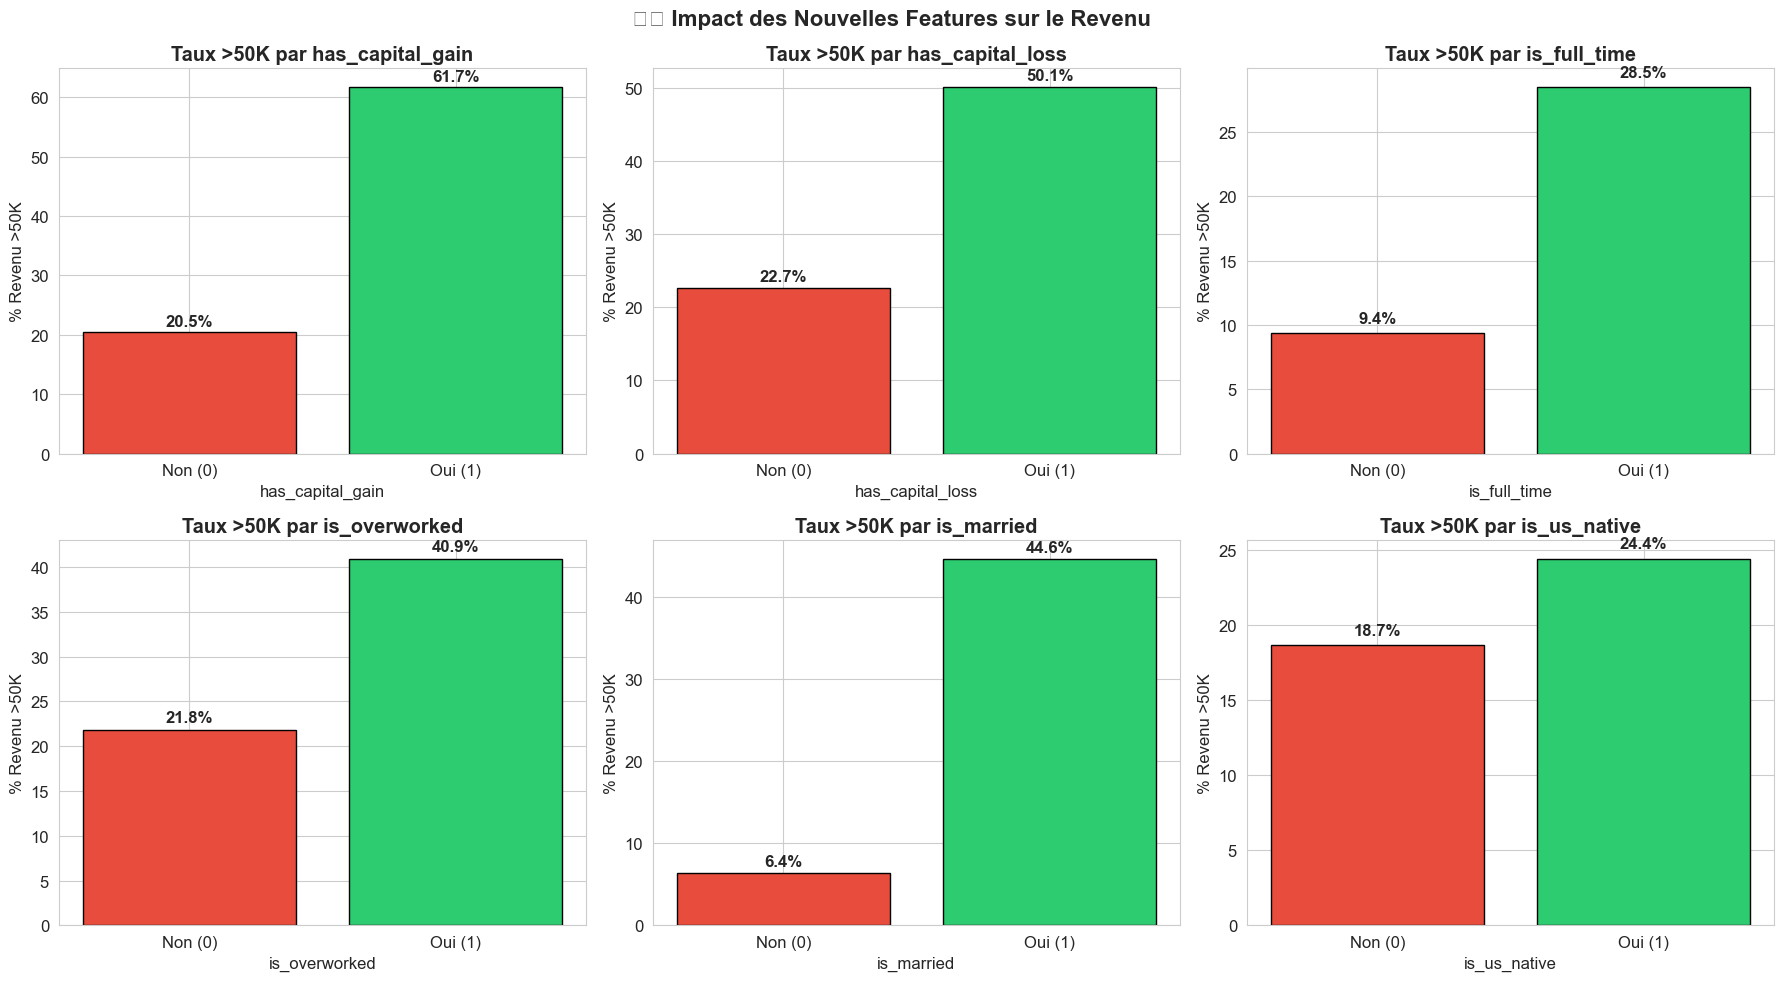

In [26]:
# Analyse de l'impact des nouvelles features
new_features = ['has_capital_gain', 'has_capital_loss', 'is_full_time', 
                'is_overworked', 'is_married', 'is_us_native']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, feat in enumerate(new_features):
    rate = df_fe.groupby(feat)['income_binary'].mean() * 100
    colors = ['#e74c3c' if v == 0 else '#2ecc71' for v in rate.index]
    bars = axes[i].bar(rate.index, rate.values, color=colors, edgecolor='black')
    axes[i].set_title(f'Taux >50K par {feat}', fontweight='bold')
    axes[i].set_xlabel(feat)
    axes[i].set_ylabel('% Revenu >50K')
    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(['Non (0)', 'Oui (1)'])
    for bar, val in zip(bars, rate.values):
        axes[i].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.5,
                    f'{val:.1f}%', ha='center', va='bottom', fontweight='bold')

plt.suptitle('🛠️ Impact des Nouvelles Features sur le Revenu', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('10_feature_engineering.png', bbox_inches='tight', dpi=150)
plt.show()

---
## 🎯 PHASE 5 — Feature Selection

In [27]:
# Préparation du dataset final pour la sélection de features
df_final = df_fe.copy()

# Suppression de fnlwgt (poids statistique, non prédictif)
df_final = df_final.drop(columns=['fnlwgt'])
print(f'✅ fnlwgt supprimé (poids statistique de recensement, non pertinent pour prédiction)')

# Suppression de native_country (remplacée par is_us_native)
df_final = df_final.drop(columns=['native_country'])
print(f'✅ native_country supprimé (remplacée par is_us_native)')

# Suppression de marital_status original (remplacé par is_married)
df_final = df_final.drop(columns=['marital_status'])
print(f'✅ marital_status supprimé (remplacé par is_married)')

# Suppression de age_group (on garde age numérique)
df_final = df_final.drop(columns=['age_group'])

# Encodage des variables catégorielles restantes
cat_remaining = df_final.select_dtypes(include='object').columns.tolist()
cat_remaining.remove('income_binary') if 'income_binary' in cat_remaining else None
print(f'\n📋 Variables catégorielles restantes : {cat_remaining}')

df_final = pd.get_dummies(df_final, columns=cat_remaining, drop_first=True)
print(f'\n✅ Encodage OHE terminé. Shape : {df_final.shape}')

# Séparation X et y
X = df_final.drop(columns=['income_binary'])
y = df_final['income_binary']

print(f'\n📊 Dimensions :')
print(f'   X (features) : {X.shape}')
print(f'   y (cible)    : {y.shape}')
print(f'   Proportion >50K : {y.mean()*100:.1f}%')

✅ fnlwgt supprimé (poids statistique de recensement, non pertinent pour prédiction)
✅ native_country supprimé (remplacée par is_us_native)
✅ marital_status supprimé (remplacé par is_married)

📋 Variables catégorielles restantes : ['workclass', 'occupation', 'relationship', 'race', 'sex']

✅ Encodage OHE terminé. Shape : (48789, 43)

📊 Dimensions :
   X (features) : (48789, 42)
   y (cible)    : (48789,)
   Proportion >50K : 23.9%


In [28]:
# ── Méthode 1 : Importance des features (RandomForest) ──────────────────────
from sklearn.preprocessing import LabelEncoder

# Assurer que tout est numérique
X_num = X.select_dtypes(include=[np.number])
X_num = X_num.fillna(X_num.median())

rf_selector = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_selector.fit(X_num, y)

feature_importance = pd.DataFrame({
    'Feature': X_num.columns,
    'Importance': rf_selector.feature_importances_
}).sort_values('Importance', ascending=False)

print('📊 Top 20 Features selon Random Forest :')
print(feature_importance.head(20).to_string(index=False))

📊 Top 20 Features selon Random Forest :
         Feature  Importance
             age    0.234545
      is_married    0.206796
   education_num    0.161434
     net_capital    0.127653
  hours_per_week    0.099356
    capital_gain    0.091073
    capital_loss    0.033224
has_capital_gain    0.016790
    is_full_time    0.011000
    is_us_native    0.008021
has_capital_loss    0.006339
   is_overworked    0.003769


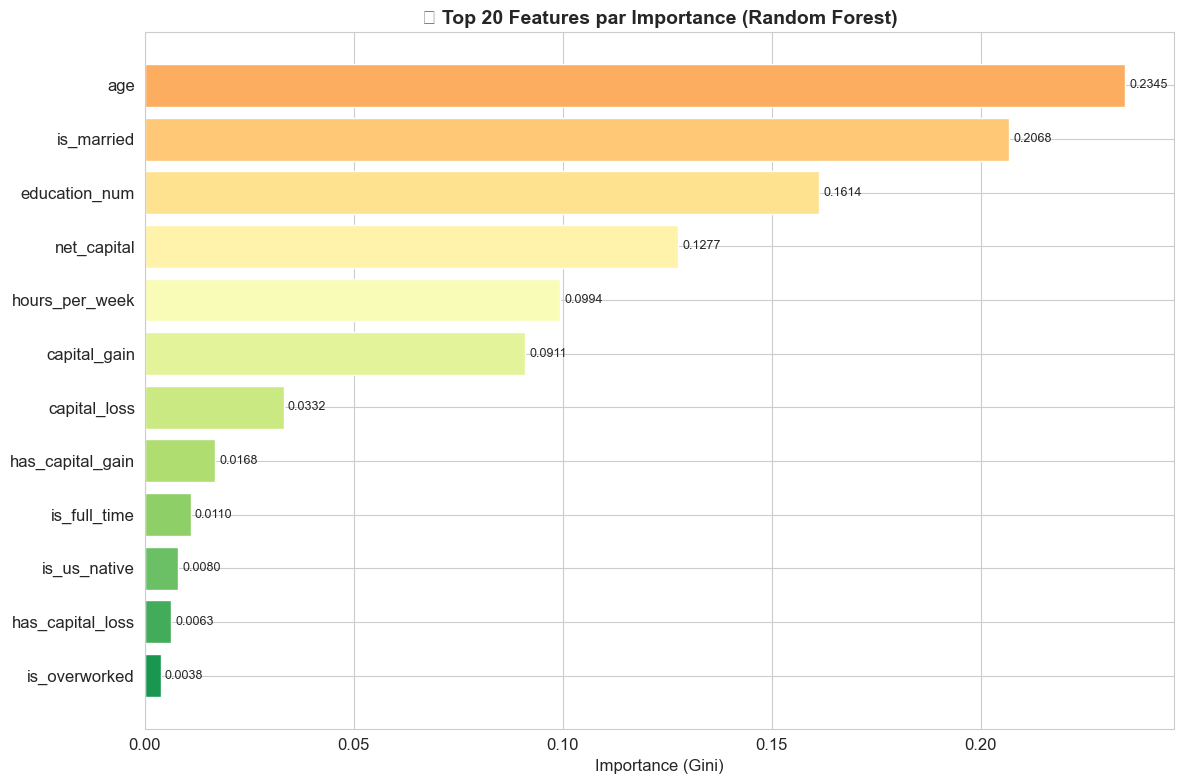

In [29]:
# Visualisation des importances
top_20 = feature_importance.head(20)

plt.figure(figsize=(12, 8))
colors = plt.cm.RdYlGn(np.linspace(0.3, 0.9, len(top_20)))
bars = plt.barh(top_20['Feature'][::-1], top_20['Importance'][::-1], color=colors[::-1])
plt.title('🎯 Top 20 Features par Importance (Random Forest)', fontsize=14, fontweight='bold')
plt.xlabel('Importance (Gini)')
for bar, val in zip(bars, top_20['Importance'][::-1]):
    plt.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2.,
            f'{val:.4f}', va='center', fontsize=9)
plt.tight_layout()
plt.savefig('11_feature_importance.png', bbox_inches='tight', dpi=150)
plt.show()

In [30]:
# ── Méthode 2 : SelectKBest avec Mutual Information ──────────────────────────
selector_mi = SelectKBest(score_func=mutual_info_classif, k=15)
selector_mi.fit(X_num, y)

mi_scores = pd.DataFrame({
    'Feature': X_num.columns,
    'MI_Score': selector_mi.scores_
}).sort_values('MI_Score', ascending=False)

print('📊 Top 15 Features selon Mutual Information :')
print(mi_scores.head(15).to_string(index=False))

# Sélection finale : features communes aux 2 méthodes (top 15)
top_rf = set(feature_importance.head(15)['Feature'])
top_mi = set(mi_scores.head(15)['Feature'])
selected_features = list(top_rf.union(top_mi))

print(f'\n✅ Features sélectionnées (union RF + MI) : {len(selected_features)}')
print(selected_features)

📊 Top 15 Features selon Mutual Information :
         Feature  MI_Score
     net_capital  0.118854
      is_married  0.108913
    capital_gain  0.080404
             age  0.069952
   education_num  0.065153
  hours_per_week  0.039820
    capital_loss  0.036237
has_capital_gain  0.030801
    is_full_time  0.028047
   is_overworked  0.009962
    is_us_native  0.003505
has_capital_loss  0.003140

✅ Features sélectionnées (union RF + MI) : 12
['hours_per_week', 'has_capital_gain', 'is_full_time', 'has_capital_loss', 'is_overworked', 'is_us_native', 'capital_gain', 'age', 'education_num', 'capital_loss', 'is_married', 'net_capital']


In [31]:
# Préparation du dataset final avec features sélectionnées
X_selected = X_num[selected_features]

# Standardisation
scaler_final = StandardScaler()
X_scaled = pd.DataFrame(scaler_final.fit_transform(X_selected), columns=selected_features)

print(f'✅ Dataset final pour modélisation :')
print(f'   X_scaled shape : {X_scaled.shape}')
print(f'   y shape        : {y.shape}')

✅ Dataset final pour modélisation :
   X_scaled shape : (48789, 12)
   y shape        : (48789,)


---
## 📉 PHASE 6 — ACP (Analyse en Composantes Principales)

In [32]:
# ── 6.1 ACP complète ────────────────────────────────────────────────────────
pca_full = PCA(random_state=42)
pca_full.fit(X_scaled)

explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

# Trouver le nombre de composantes pour 80%, 90%, 95%
n_80 = np.argmax(cumulative_variance >= 0.80) + 1
n_90 = np.argmax(cumulative_variance >= 0.90) + 1
n_95 = np.argmax(cumulative_variance >= 0.95) + 1

print(f'📊 Analyse de la Variance Expliquée :')
print(f'   - {n_80} composantes expliquent 80% de la variance')
print(f'   - {n_90} composantes expliquent 90% de la variance')
print(f'   - {n_95} composantes expliquent 95% de la variance')

📊 Analyse de la Variance Expliquée :
   - 6 composantes expliquent 80% de la variance
   - 8 composantes expliquent 90% de la variance
   - 9 composantes expliquent 95% de la variance


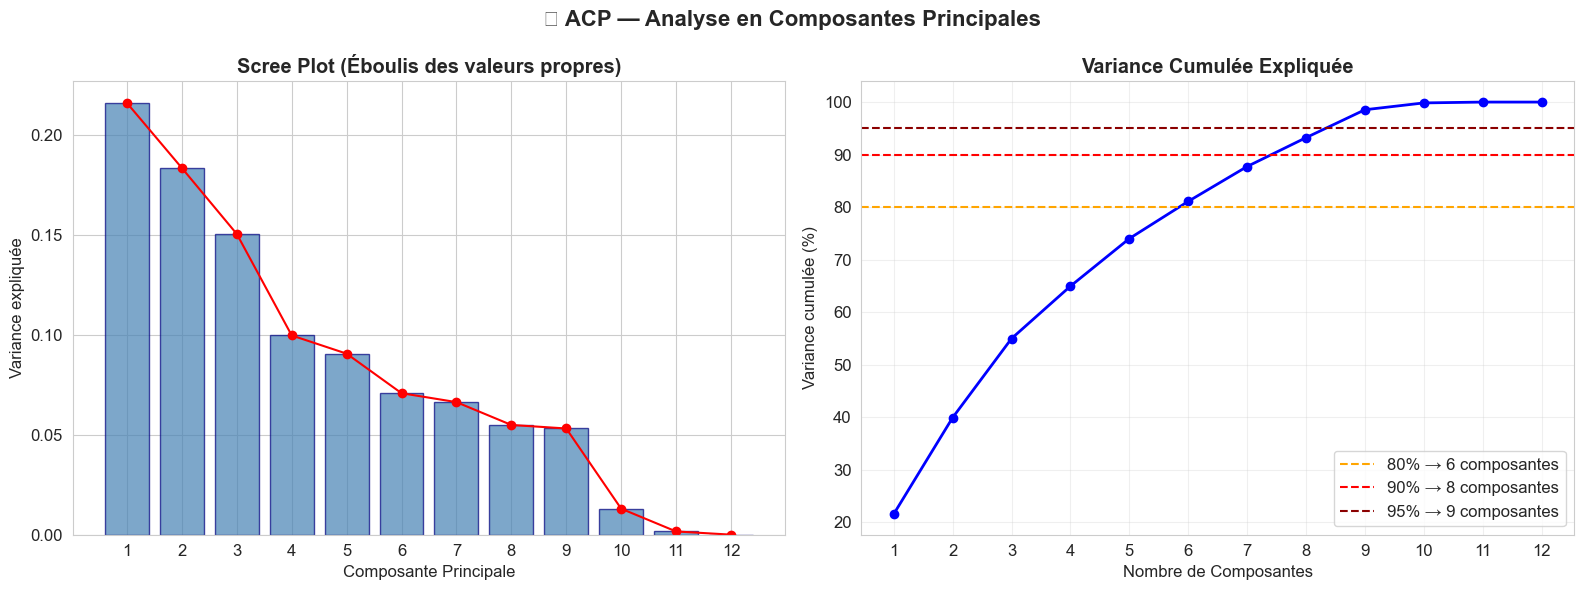

In [33]:
# Scree Plot + Variance cumulée
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Scree plot (Éboulis)
axes[0].bar(range(1, len(explained_variance)+1), explained_variance, 
           color='steelblue', alpha=0.7, edgecolor='navy')
axes[0].plot(range(1, len(explained_variance)+1), explained_variance, 
            'ro-', markersize=6)
axes[0].set_title('Scree Plot (Éboulis des valeurs propres)', fontweight='bold')
axes[0].set_xlabel('Composante Principale')
axes[0].set_ylabel('Variance expliquée')
axes[0].set_xticks(range(1, len(explained_variance)+1))

# Variance cumulée
axes[1].plot(range(1, len(cumulative_variance)+1), cumulative_variance * 100, 
            'bo-', markersize=6, linewidth=2)
axes[1].axhline(y=80, color='orange', linestyle='--', label=f'80% → {n_80} composantes')
axes[1].axhline(y=90, color='red', linestyle='--', label=f'90% → {n_90} composantes')
axes[1].axhline(y=95, color='darkred', linestyle='--', label=f'95% → {n_95} composantes')
axes[1].set_title('Variance Cumulée Expliquée', fontweight='bold')
axes[1].set_xlabel('Nombre de Composantes')
axes[1].set_ylabel('Variance cumulée (%)')
axes[1].legend()
axes[1].set_xticks(range(1, len(cumulative_variance)+1))
axes[1].grid(True, alpha=0.3)

plt.suptitle('📉 ACP — Analyse en Composantes Principales', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('12_pca_scree.png', bbox_inches='tight', dpi=150)
plt.show()

In [34]:
# ── 6.2 Application de l'ACP avec n_95 composantes ─────────────────────────
pca = PCA(n_components=n_90, random_state=42)  # On choisit 90% de variance
X_pca = pca.fit_transform(X_scaled)

print(f'✅ ACP appliquée :')
print(f'   X original : {X_scaled.shape}')
print(f'   X réduit   : {X_pca.shape}')
print(f'   Réduction  : {X_scaled.shape[1]} → {X_pca.shape[1]} dimensions')
print(f'   Variance conservée : {pca.explained_variance_ratio_.sum()*100:.2f}%')

✅ ACP appliquée :
   X original : (48789, 12)
   X réduit   : (48789, 8)
   Réduction  : 12 → 8 dimensions
   Variance conservée : 93.23%


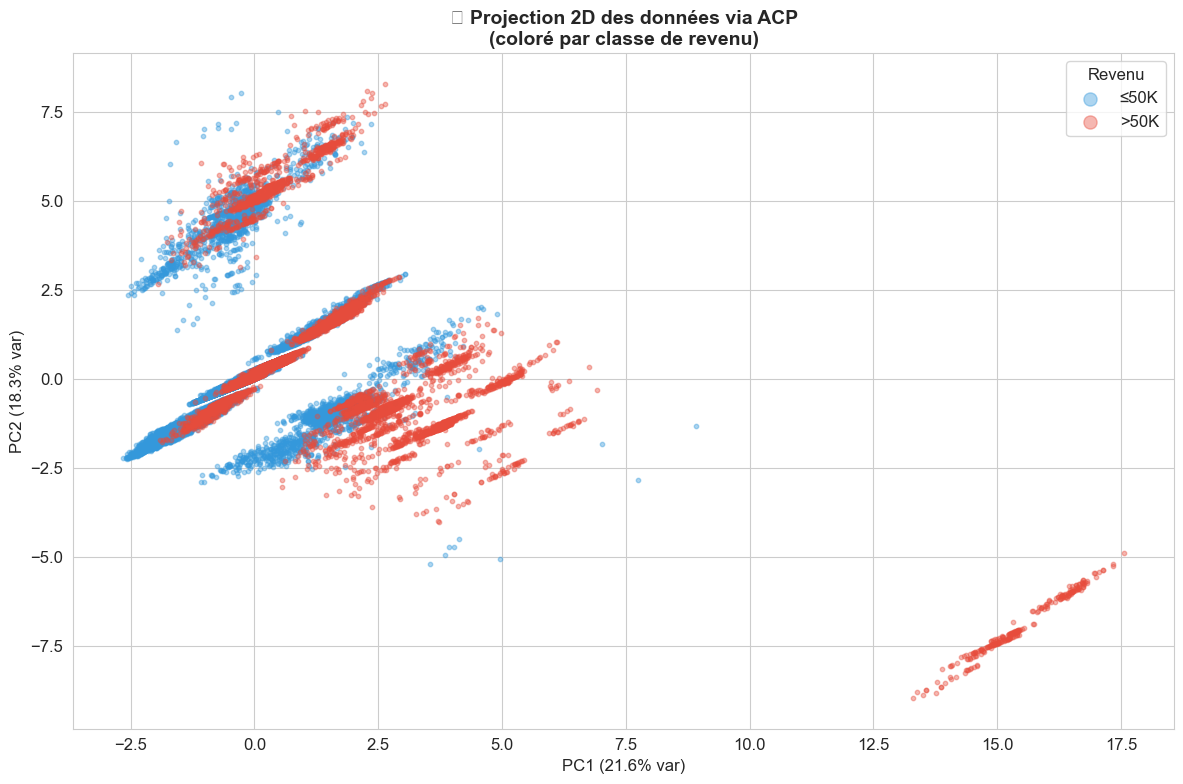

In [35]:
# ── 6.3 Visualisation 2D des données dans l'espace PCA ───────────────────────
pca_2d = PCA(n_components=2, random_state=42)
X_pca_2d = pca_2d.fit_transform(X_scaled)

plt.figure(figsize=(12, 8))
colors = {0: '#3498db', 1: '#e74c3c'}
labels = {0: '≤50K', 1: '>50K'}

for label, color in colors.items():
    mask = y.values == label
    plt.scatter(X_pca_2d[mask, 0], X_pca_2d[mask, 1],
               c=color, label=labels[label], alpha=0.4, s=10)

plt.xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}% var)', fontsize=12)
plt.ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}% var)', fontsize=12)
plt.title('📉 Projection 2D des données via ACP\n(coloré par classe de revenu)', 
          fontsize=14, fontweight='bold')
plt.legend(title='Revenu', fontsize=12, markerscale=3)
plt.tight_layout()
plt.savefig('13_pca_2d.png', bbox_inches='tight', dpi=150)
plt.show()

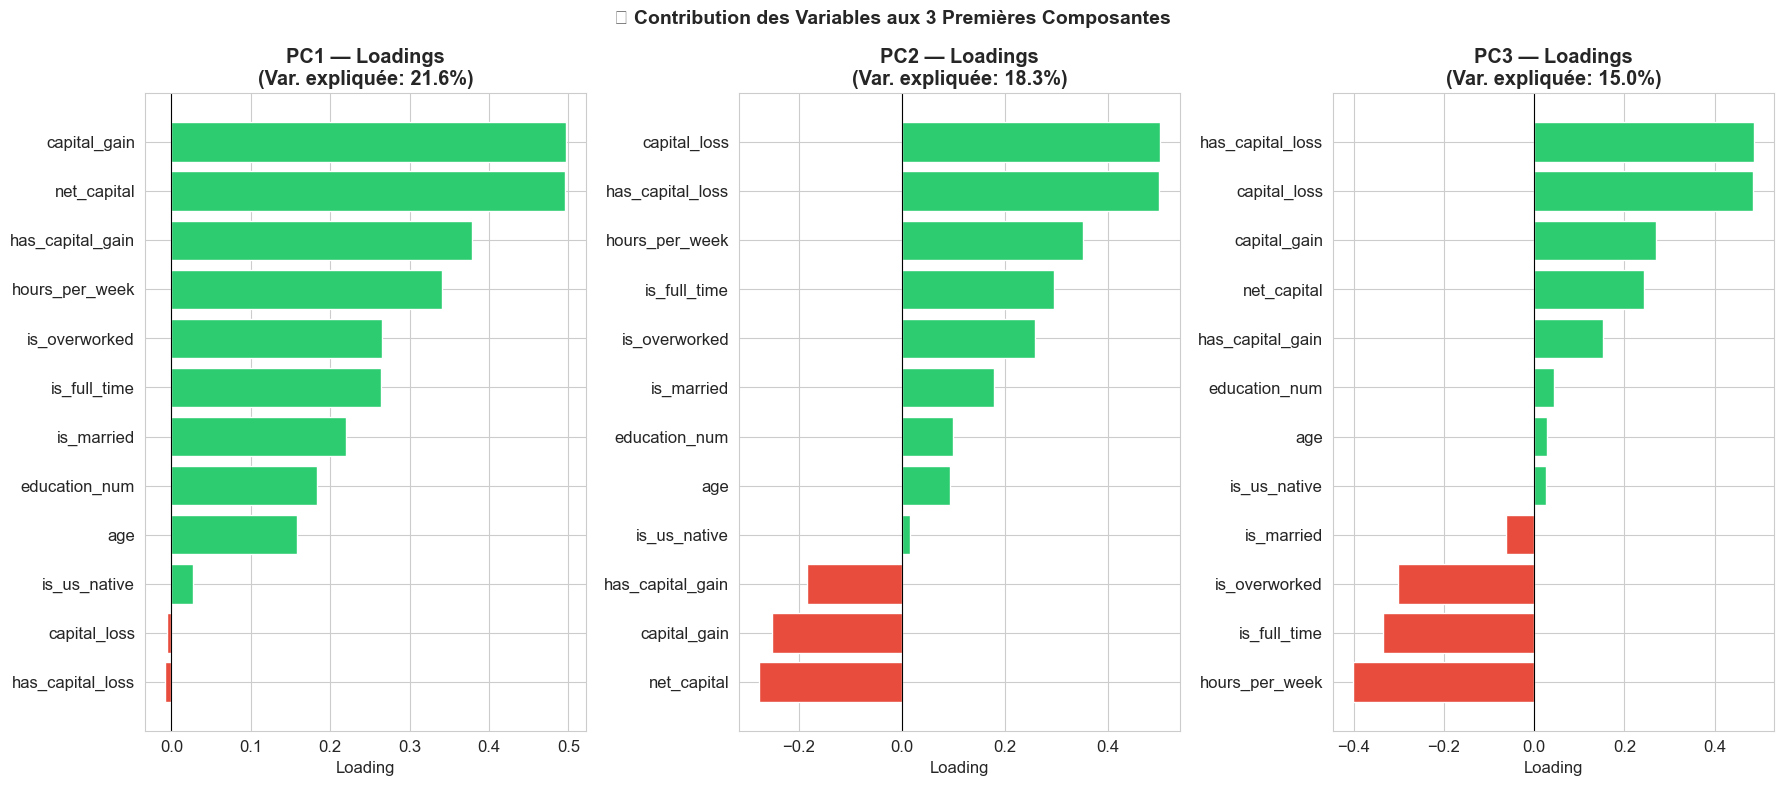

In [36]:
# ── 6.4 Loadings : contribution des variables aux composantes ────────────────
loadings = pd.DataFrame(
    pca_full.components_[:3].T,
    columns=['PC1', 'PC2', 'PC3'],
    index=selected_features
)

fig, axes = plt.subplots(1, 3, figsize=(18, 8))

for i, pc in enumerate(['PC1', 'PC2', 'PC3']):
    sorted_loadings = loadings[pc].sort_values()
    colors = ['#e74c3c' if v < 0 else '#2ecc71' for v in sorted_loadings]
    axes[i].barh(sorted_loadings.index, sorted_loadings.values, color=colors)
    axes[i].set_title(f'{pc} — Loadings\n(Var. expliquée: {pca_full.explained_variance_ratio_[i]*100:.1f}%)',
                     fontweight='bold')
    axes[i].axvline(x=0, color='black', linewidth=0.8)
    axes[i].set_xlabel('Loading')

plt.suptitle('📊 Contribution des Variables aux 3 Premières Composantes', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('14_pca_loadings.png', bbox_inches='tight', dpi=150)
plt.show()

---
## 🤖 PHASE 7 — Entraînement & Évaluation des Modèles

In [37]:
# ── 7.1 Préparation des données ──────────────────────────────────────────────
# On utilisera 2 versions : avec features originales (X_scaled) et avec ACP (X_pca)

X_pca_df = pd.DataFrame(X_pca, columns=[f'PC{i+1}' for i in range(X_pca.shape[1])])
y_reset = y.reset_index(drop=True)

# Split train/test
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_reset, test_size=0.2, random_state=42, stratify=y_reset
)

X_train_pca, X_test_pca, _, _ = train_test_split(
    X_pca_df, y_reset, test_size=0.2, random_state=42, stratify=y_reset
)

print(f'✅ Données divisées :')
print(f'   Entraînement : {X_train.shape[0]:,} samples ({y_train.mean()*100:.1f}% >50K)')
print(f'   Test         : {X_test.shape[0]:,} samples ({y_test.mean()*100:.1f}% >50K)')

✅ Données divisées :
   Entraînement : 39,031 samples (23.9% >50K)
   Test         : 9,758 samples (23.9% >50K)


In [38]:
# ── 7.2 Définition des modèles ───────────────────────────────────────────────
models = {
    'Régression Logistique'      : LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'),
    'Arbre de Décision'          : DecisionTreeClassifier(max_depth=10, random_state=42, class_weight='balanced'),
    'Random Forest'              : RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1, class_weight='balanced'),
    'Gradient Boosting'          : GradientBoostingClassifier(n_estimators=100, random_state=42),
    'K-Nearest Neighbors'        : KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    'Naive Bayes'                : GaussianNB(),
}

print('📋 Modèles à évaluer :')
for name in models:
    print(f'   - {name}')

📋 Modèles à évaluer :
   - Régression Logistique
   - Arbre de Décision
   - Random Forest
   - Gradient Boosting
   - K-Nearest Neighbors
   - Naive Bayes


In [39]:
# ── 7.3 Entraînement et évaluation (sans ACP) ────────────────────────────────
results = []

print('🚀 Entraînement des modèles (features originales)...')
print('='*70)

for name, model in models.items():
    # Cross-validation
    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='roc_auc', n_jobs=-1)
    
    # Entraînement final
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1] if hasattr(model, 'predict_proba') else None
    
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba) if y_proba is not None else None
    
    results.append({
        'Modèle': name,
        'Accuracy': acc,
        'F1-Score': f1,
        'Precision': prec,
        'Recall': rec,
        'AUC-ROC': auc,
        'CV AUC (mean)': cv_scores.mean(),
        'CV AUC (std)': cv_scores.std()
    })
    
    auc_str = f'{auc:.4f}' if auc is not None else 'N/A'
    print(f'OK {name:<30} | Acc: {acc:.4f} | F1: {f1:.4f} | AUC: {auc_str} | CV: {cv_scores.mean():.4f}+-{cv_scores.std():.4f}')

results_df = pd.DataFrame(results).sort_values('AUC-ROC', ascending=False)
print('\n📊 Tableau de Résultats :')
print(results_df.round(4).to_string(index=False))

🚀 Entraînement des modèles (features originales)...


OK Régression Logistique          | Acc: 0.7978 | F1: 0.6683 | AUC: 0.9016 | CV: 0.8989+-0.0047


OK Arbre de Décision              | Acc: 0.8024 | F1: 0.6810 | AUC: 0.9058 | CV: 0.9000+-0.0037


OK Random Forest                  | Acc: 0.8224 | F1: 0.6747 | AUC: 0.8925 | CV: 0.8850+-0.0054


OK Gradient Boosting              | Acc: 0.8644 | F1: 0.6799 | AUC: 0.9197 | CV: 0.9158+-0.0035


OK K-Nearest Neighbors            | Acc: 0.8352 | F1: 0.6362 | AUC: 0.8614 | CV: 0.8583+-0.0052


OK Naive Bayes                    | Acc: 0.7882 | F1: 0.4182 | AUC: 0.8460 | CV: 0.8451+-0.0037

📊 Tableau de Résultats :
               Modèle  Accuracy  F1-Score  Precision  Recall  AUC-ROC  CV AUC (mean)  CV AUC (std)
    Gradient Boosting    0.8644    0.6799     0.7819  0.6015   0.9197         0.9158        0.0035
    Arbre de Décision    0.8024    0.6810     0.5550  0.8810   0.9058         0.9000        0.0037
Régression Logistique    0.7978    0.6683     0.5502  0.8510   0.9016         0.8989        0.0047
        Random Forest    0.8224    0.6747     0.6008  0.7693   0.8925         0.8850        0.0054
  K-Nearest Neighbors    0.8352    0.6362     0.6747  0.6019   0.8614         0.8583        0.0052
          Naive Bayes    0.7882    0.4182     0.6105  0.3181   0.8460         0.8451        0.0037


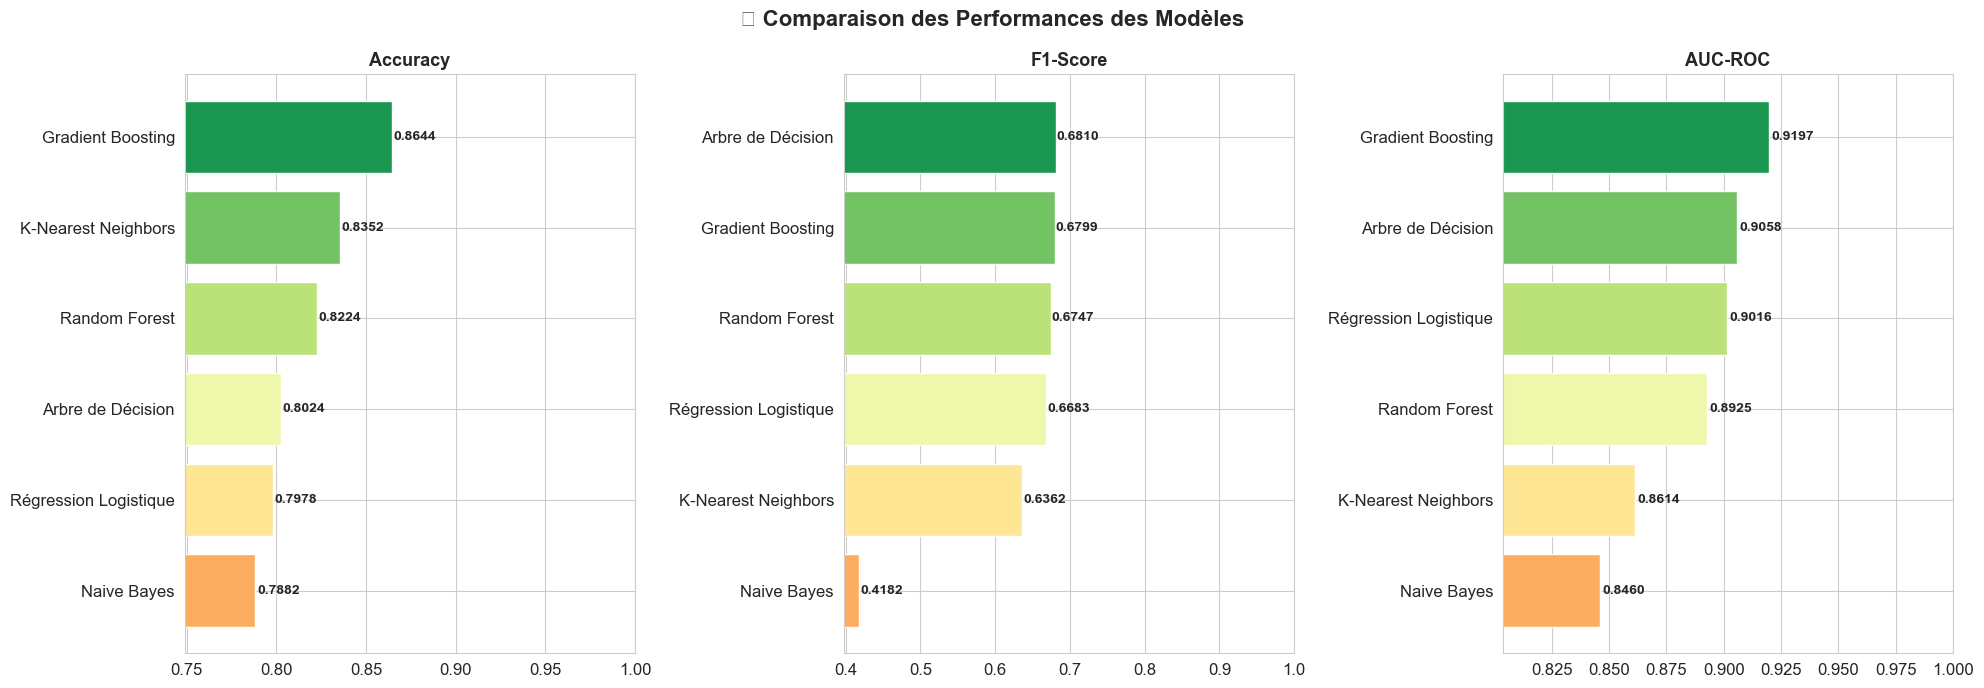

In [40]:
# ── 7.4 Comparaison visuelle des performances ────────────────────────────────
metrics = ['Accuracy', 'F1-Score', 'AUC-ROC']

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

for i, metric in enumerate(metrics):
    sorted_df = results_df.sort_values(metric, ascending=True)
    colors = plt.cm.RdYlGn(np.linspace(0.3, 0.9, len(sorted_df)))
    bars = axes[i].barh(sorted_df['Modèle'], sorted_df[metric], color=colors)
    axes[i].set_title(f'{metric}', fontweight='bold', fontsize=13)
    axes[i].set_xlim(sorted_df[metric].min() * 0.95, 1.0)
    for bar, val in zip(bars, sorted_df[metric]):
        axes[i].text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2.,
                    f'{val:.4f}', va='center', fontsize=10, fontweight='bold')

plt.suptitle('🏆 Comparaison des Performances des Modèles', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('15_model_comparison.png', bbox_inches='tight', dpi=150)
plt.show()

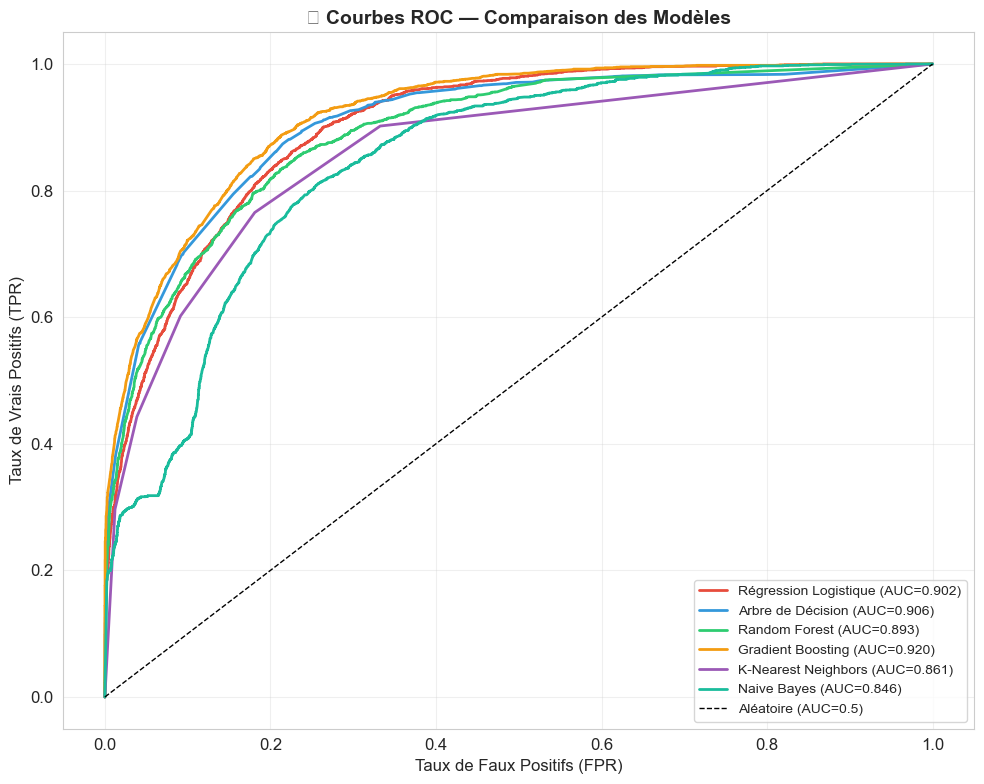

In [41]:
# ── 7.5 Courbes ROC ─────────────────────────────────────────────────────────
plt.figure(figsize=(10, 8))

colors_roc = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12', '#9b59b6', '#1abc9c']

for (name, model), color in zip(models.items(), colors_roc):
    if hasattr(model, 'predict_proba'):
        y_proba = model.predict_proba(X_test)[:, 1]
        fpr, tpr, _ = roc_curve(y_test, y_proba)
        auc = roc_auc_score(y_test, y_proba)
        plt.plot(fpr, tpr, color=color, linewidth=2, label=f'{name} (AUC={auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Aléatoire (AUC=0.5)')
plt.xlabel('Taux de Faux Positifs (FPR)', fontsize=12)
plt.ylabel('Taux de Vrais Positifs (TPR)', fontsize=12)
plt.title('📈 Courbes ROC — Comparaison des Modèles', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('16_roc_curves.png', bbox_inches='tight', dpi=150)
plt.show()

🏆 Meilleur modèle : Gradient Boosting

📋 Rapport de classification :
              precision    recall  f1-score   support

       <=50K       0.88      0.95      0.91      7422
        >50K       0.78      0.60      0.68      2336

    accuracy                           0.86      9758
   macro avg       0.83      0.77      0.80      9758
weighted avg       0.86      0.86      0.86      9758



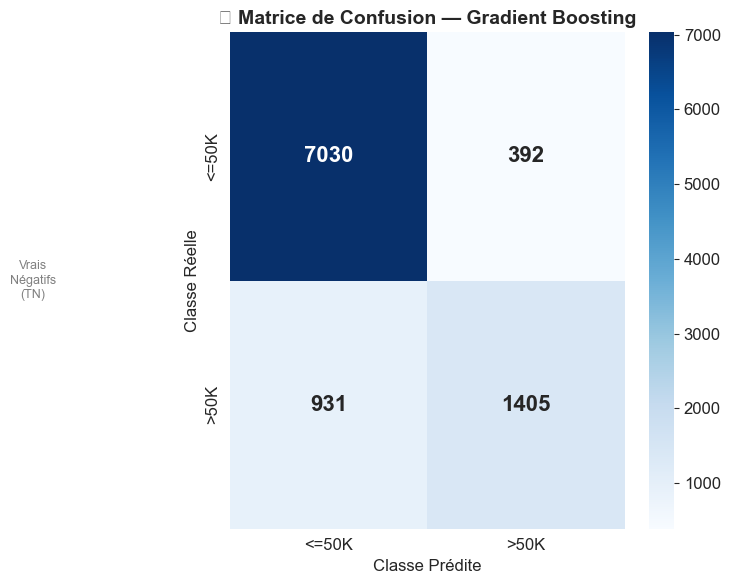

In [42]:
# ── 7.6 Meilleur modèle — Matrice de Confusion & Rapport complet ─────────────
best_model_name = results_df.iloc[0]['Modèle']
best_model = models[best_model_name]

y_pred_best = best_model.predict(X_test)

print(f'🏆 Meilleur modèle : {best_model_name}')
print('='*60)
print('\n📋 Rapport de classification :')
print(classification_report(y_test, y_pred_best, target_names=['<=50K', '>50K']))

# Matrice de confusion
cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['<=50K', '>50K'],
            yticklabels=['<=50K', '>50K'],
            annot_kws={'size': 16, 'weight': 'bold'})
plt.title(f'🔷 Matrice de Confusion — {best_model_name}', fontsize=14, fontweight='bold')
plt.ylabel('Classe Réelle', fontsize=12)
plt.xlabel('Classe Prédite', fontsize=12)

# Ajout des labels détaillés
plt.text(-0.5, 0.5, 'Vrais\nNégatifs\n(TN)', ha='center', va='center', 
         fontsize=9, color='gray', transform=plt.gca().transAxes)

plt.tight_layout()
plt.savefig('17_confusion_matrix.png', bbox_inches='tight', dpi=150)
plt.show()

In [43]:
# ── 7.7 Comparaison : avec/sans ACP ─────────────────────────────────────────
print('🔬 Comparaison performances : Features originales vs ACP')
print('='*65)

comparison_results = []

for name in ['Régression Logistique', 'Random Forest', 'Gradient Boosting']:
    model = models[name]
    
    # Avec features originales
    model.fit(X_train, y_train)
    auc_orig = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
    
    # Avec ACP
    model.fit(X_train_pca, y_train)
    auc_pca = roc_auc_score(y_test, model.predict_proba(X_test_pca)[:, 1])
    
    comparison_results.append({
        'Modèle': name,
        f'AUC (Features originales, {X_scaled.shape[1]}D)': round(auc_orig, 4),
        f'AUC (ACP {n_90} composantes)': round(auc_pca, 4),
        'Différence': round(auc_orig - auc_pca, 4)
    })
    
    print(f'{name:<30} | Original: {auc_orig:.4f} | ACP: {auc_pca:.4f} | Δ={auc_orig-auc_pca:+.4f}')

print('\n💡 Conclusion : La perte de performance avec ACP est minime,')
print(f'   mais on réduit la dimensionnalité de {X_scaled.shape[1]} → {n_90} dimensions.')

🔬 Comparaison performances : Features originales vs ACP


Régression Logistique          | Original: 0.9016 | ACP: 0.8924 | Δ=+0.0092


Random Forest                  | Original: 0.8925 | ACP: 0.8782 | Δ=+0.0143


Gradient Boosting              | Original: 0.9197 | ACP: 0.9047 | Δ=+0.0150

💡 Conclusion : La perte de performance avec ACP est minime,
   mais on réduit la dimensionnalité de 12 → 8 dimensions.


In [44]:
# ── 7.8 Résumé final ─────────────────────────────────────────────────────────
print('\n' + '='*70)
print('🎓 RÉSUMÉ FINAL DU PROJET ML — Adult Census Income')
print('='*70)
print()
print('📊 DATASET :')
print(f'   - Source : UCI Census Income (1994)')
print(f'   - Taille : {df.shape[0]:,} instances × {df.shape[1]} features')
print(f'   - Cible  : Prédire revenu >50K (classification binaire)')
print(f'   - Déséquilibre : 76% ≤50K / 24% >50K')
print()
print('🧹 DATA CLEANING :')
print(f'   - Valeurs manquantes (?) traitées par imputation mode')
print(f'   - Outliers : capping de hours_per_week à 99h')
print(f'   - Redondance : suppression de "education" (=="education_num")')
print(f'   - Doublons : {n_duplicates} supprimés')
print()
print('🛠️ FEATURE ENGINEERING :')
print(f'   - 8 nouvelles features créées (has_capital_gain, is_married, etc.)')
print()
print('🎯 FEATURE SELECTION :')
print(f'   - Méthode Random Forest + Mutual Information')
print(f'   - {len(selected_features)} features retenues')
print()
print('📉 ACP :')
print(f'   - {n_90} composantes retenues (90% de variance expliquée)')
print(f'   - Réduction {X_scaled.shape[1]}D → {n_90}D')
print()
print('🏆 MEILLEUR MODÈLE :')
best = results_df.iloc[0]
print(f'   - {best["Modèle"]}')
print(f'   - Accuracy : {best["Accuracy"]:.4f}')
print(f'   - F1-Score : {best["F1-Score"]:.4f}')
print(f'   - AUC-ROC  : {best["AUC-ROC"]:.4f}')
print('='*70)


🎓 RÉSUMÉ FINAL DU PROJET ML — Adult Census Income

📊 DATASET :
   - Source : UCI Census Income (1994)
   - Taille : 48,842 instances × 15 features
   - Cible  : Prédire revenu >50K (classification binaire)
   - Déséquilibre : 76% ≤50K / 24% >50K

🧹 DATA CLEANING :
   - Valeurs manquantes (?) traitées par imputation mode
   - Outliers : capping de hours_per_week à 99h
   - Redondance : suppression de "education" (=="education_num")
   - Doublons : 53 supprimés

🛠️ FEATURE ENGINEERING :
   - 8 nouvelles features créées (has_capital_gain, is_married, etc.)

🎯 FEATURE SELECTION :
   - Méthode Random Forest + Mutual Information
   - 12 features retenues

📉 ACP :
   - 8 composantes retenues (90% de variance expliquée)
   - Réduction 12D → 8D

🏆 MEILLEUR MODÈLE :
   - Gradient Boosting
   - Accuracy : 0.8644
   - F1-Score : 0.6799
   - AUC-ROC  : 0.9197
